# TP3 - Procesamiento del Lenguaje Natural (NLP)
**Inteligencia Artificial y Neurociencias**

## 4. Large Language Models (LLMs)

En esta parte se evalúa un **LLM generativo ejecutado localmente, Qwen2.5-1.5B-Instruct** (`Qwen/Qwen2.5-1.5B-Instruct`), **sin ningún tipo de fine-tuning**: toda la adaptación a la tarea se hace mediante el *prompt*. Se exploran:

1. **Zero-shot:** distintas instrucciones (con y sin el título de la propuesta, con y sin definiciones de las clases, en español y en inglés).
2. **Few-shot:** se agregan ejemplos de train como turnos previos de la conversación. Se cruzan tres decisiones: **mostrar o no la propuesta** en el prompt, **cómo elegir los ejemplos** (balanceados por clase o en la proporción real de clases) y **cuántos ejemplos** usar (3, 6 y 12 en total). Cada selección se repite con 3 semillas para medir cuánto depende el resultado de qué ejemplos tocaron.
3. **Calibración:** como el método de predicción devuelve probabilidades, se comparan tres formas de corregir el sesgo del modelo hacia ciertas etiquetas: con entradas vacías (*contextual calibration*), con el promedio del propio conjunto (*batch calibration*) y con un sesgo por clase ajustado sobre 200 comentarios de train.

**Cómo se obtiene la predicción (scoring de etiquetas).** En lugar de dejar que el modelo genere texto libre y parsearlo, se le pide que responda con una sola palabra (`favor`, `contra` o `neutral`) y se mira la **probabilidad que el modelo asigna a cada etiqueta como primer token de la respuesta**. La predicción es la etiqueta más probable. Ventajas: nunca hay respuestas inválidas, se necesita una sola pasada hacia adelante por comentario (no hay decodificación autoregresiva) y se obtienen probabilidades, que permiten calibrar.

**Protocolo de evaluación** (el mismo de las partes 1 a 3):
- Se usan exactamente los conjuntos de `splits_tp3.csv` (split agrupado por propuesta, ≈70/15/15). Los ejemplos few-shot y la muestra para ajustar la calibración se toman **solo de train**.
- Todas las decisiones (instrucción, ejemplos, calibración) se toman con **validación**. El conjunto de **test se usa una única vez**, al final (sección 4.7).
- Métrica principal: **Macro-F1** respecto de `majority_label`. Se reportan además accuracy, F1 por clase, tiempo de inferencia, cantidad de tokens por prompt y uso de VRAM.

> **Para correr en Colab:** activar la GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*) y subir `splits_tp3.csv` (generado por la parte 1). Opcionalmente, subir `resultados_parte2_test.csv` y `resultados_parte3_test.csv` para la comparación de la sección 4.8.4. El modelo no requiere token de Hugging Face. Todo el notebook tarda aproximadamente 45–50 minutos en una T4 (la mayor parte es el few-shot con 12 ejemplos).

### 4.0. Configuración

In [1]:
!pip -q install datasets

In [2]:
import os
import gc
import time
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

import sklearn
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
CLASES = ["favor", "against", "neutral"]   # mismo orden que en las partes 1 a 3
MODELO_LLM = "Qwen/Qwen2.5-1.5B-Instruct"

sns.set_theme(style="whitegrid")

def fijar_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

fijar_semilla(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32   # la T4 no soporta bf16 de forma eficiente

def sincronizar():
    """Espera a que termine el trabajo en la GPU (necesario para medir tiempos correctamente)."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

# Hardware / versiones (para reportar costos)
print("Python:", platform.python_version(), "| torch:", torch.__version__,
      "| transformers:", transformers.__version__, "| scikit-learn:", sklearn.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
if DEVICE.type == "cuda":
    prop = torch.cuda.get_device_properties(0)
    print(f"GPU: {prop.name} | VRAM total: {prop.total_memory / 1e9:.1f} GB")
else:
    print("ATENCIÓN: no hay GPU disponible. La inferencia del LLM en CPU es muy lenta; "
          "activar la GPU en Colab antes de seguir.")

Python: 3.13.16 | torch: 2.14.1+cu130 | transformers: 5.22.1 | scikit-learn: 1.6.1
CPU: x86_64 | núcleos: 2
GPU: Tesla T4 | VRAM total: 15.6 GB


### 4.1. Carga de datos y particiones

Se reconstruye `df_modelado` igual que en las partes anteriores (se descartan los 150 comentarios sin mayoría) y se asigna a cada comentario su conjunto según `splits_tp3.csv`.

In [3]:
dataset = load_dataset("SINAI/ALIA-es-discriminative-stance-detection")
df = dataset["train"].to_pandas()

cols_anotadores = ["annotation_1", "annotation_2", "annotation_3"]
df_modelado = df[df["majority_label"].isin(CLASES)].copy().reset_index(drop=True)
df_modelado["label"] = df_modelado["majority_label"]
df_modelado["id"] = df_modelado["id"].astype(str)

# Nivel de acuerdo entre anotadores (se usa en el análisis de errores)
df_modelado["max_acuerdo"] = df_modelado[cols_anotadores].apply(lambda f: f.value_counts().max(), axis=1)
df_modelado["nivel_acuerdo"] = df_modelado["max_acuerdo"].map({3: "Total (3/3)", 2: "Parcial (2/3)"})

RUTA_SPLITS = "splits_tp3.csv"
if not os.path.exists(RUTA_SPLITS):
    try:
        from google.colab import files
        print("No se encontró splits_tp3.csv: subilo (lo genera la parte 1).")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Falta splits_tp3.csv (lo genera la parte 1).")

splits = pd.read_csv(RUTA_SPLITS, dtype={"id": str})
df_modelado = df_modelado.merge(splits, on="id", how="left", validate="one_to_one")
assert df_modelado["split"].notna().all(), "Hay comentarios sin split asignado"

train_df = df_modelado[df_modelado["split"] == "train"].reset_index(drop=True)
val_df = df_modelado[df_modelado["split"] == "val"].reset_index(drop=True)
test_df = df_modelado[df_modelado["split"] == "test"].reset_index(drop=True)

# Controles: todos los comentarios tienen split y no hay propuestas compartidas
assert len(train_df) + len(val_df) + len(test_df) == len(df_modelado) == 2850
print(f"Train: {len(train_df)} | Validación: {len(val_df)} | Test: {len(test_df)}")
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not set(a["target"]) & set(b["target"])

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

display(pd.crosstab(df_modelado["split"], df_modelado["label"]).loc[["train", "val", "test"], CLASES])

README.md:   0%|          | 0.00/20.1k [00:00<?, ?B/s]

corpus_stance_detection_ALIA.jsonl:   0%|          | 0.00/4.48M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3000 [00:00<?, ? examples/s]

Train: 2019 | Validación: 413 | Test: 418


label,favor,against,neutral
split,,,
train,1262,445,312
val,261,87,65
test,257,95,66


### 4.2. Carga del modelo

Qwen2.5-1.5B-Instruct es un modelo *decoder-only* de ≈1.500 M de parámetros (≈14 veces más que BETO), entrenado con instrucciones y multilingüe (incluye español). Se carga en fp16, lo que ocupa ≈3 GB de VRAM: entra cómodo en una T4 sin cuantizar.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODELO_LLM)
tokenizer.padding_side = "right"
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id

sincronizar(); t0 = time.perf_counter()
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=DTYPE).to(DEVICE).eval()
sincronizar(); T_CARGA_S = time.perf_counter() - t0
assert next(llm.parameters()).dtype == DTYPE

N_PARAMS_M = sum(p.numel() for p in llm.parameters()) / 1e6
TAMAÑO_LLM_MB = sum(p.numel() * p.element_size() for p in llm.parameters()) / 1e6
VRAM_MODELO_GB = torch.cuda.memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan
print(f"Parámetros: {N_PARAMS_M:.0f} M | tamaño en {str(DTYPE).replace('torch.', '')}: {TAMAÑO_LLM_MB:.0f} MB | "
      f"VRAM ocupada por los pesos: {VRAM_MODELO_GB:.2f} GB | carga: {T_CARGA_S:.1f} s")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Parámetros: 1544 M | tamaño en float16: 3087 MB | VRAM ocupada por los pesos: 3.09 GB | carga: 57.6 s


### 4.3. Prompts y scoring de etiquetas

#### Instrucciones a comparar (zero-shot)

Todas las instrucciones van en el mensaje de sistema y el comentario en el mensaje de usuario, con el formato de chat del modelo (`apply_chat_template`). Se varían tres aspectos:

| Prompt | Incluye la propuesta | Definiciones de las clases | Idioma | Etiquetas |
|---|---|---|---|---|
| `basico_sin_propuesta` | No | No | Español | favor / contra / neutral |
| `basico` | Sí (título) | No | Español | favor / contra / neutral |
| `definiciones` | Sí (título) | Sí | Español | favor / contra / neutral |
| `definiciones_en` | Sí (título) | Sí | Inglés | favor / against / neutral |

- **Propuesta:** como en la parte 3, la postura se define respecto de una propuesta, así que se espera que mostrarla ayude. Se usa solo el título (la descripción es muy larga, ver parte 3).
- **Definiciones:** un modelo chico puede no tener claro qué cuenta como *neutral* (preguntas, información, comentarios ambiguos). Las definiciones explicitan el criterio.
- **Idioma:** los LLMs suelen seguir mejor las instrucciones en inglés (la mayor parte de su entrenamiento de instrucciones es en inglés), aunque los comentarios estén en español.

In [5]:
DEF_ES = """Definiciones:
- favor: el comentario apoya la propuesta, la defiende o da argumentos para que se apruebe.
- contra: el comentario rechaza o critica la propuesta, o argumenta que es innecesaria, perjudicial o inviable.
- neutral: el comentario no toma una posición clara sobre la propuesta (por ejemplo, hace una pregunta, aporta información, habla de otro tema o es ambiguo)."""

DEF_EN = """Definitions:
- favor: the comment supports the proposal, defends it or gives arguments for it to be approved.
- against: the comment rejects or criticizes the proposal, or argues that it is unnecessary, harmful or unfeasible.
- neutral: the comment does not take a clear position on the proposal (for example, it asks a question, provides information, talks about something else or is ambiguous)."""

TAREA_ES = ("Tu tarea es clasificar la postura de comentarios escritos por ciudadanos sobre propuestas "
            "publicadas en una plataforma de participación ciudadana. Indicá si el comentario está "
            "a favor de la propuesta, en contra de la propuesta o es neutral.")
TAREA_EN = ("Your task is to classify the stance of comments written by citizens about proposals published "
            "on a citizen participation platform. The proposal and the comment are in Spanish. Indicate "
            "whether the comment is in favor of the proposal, against the proposal or neutral.")
RESP_ES = "Respondé con una sola palabra: favor, contra o neutral."
RESP_EN = "Answer with a single word: favor, against or neutral."

PROMPTS = {
    "basico_sin_propuesta": {
        "idioma": "es", "con_propuesta": False,
        "system": TAREA_ES + " Solo vas a ver el comentario, no la propuesta.\n" + RESP_ES},
    "basico": {
        "idioma": "es", "con_propuesta": True,
        "system": TAREA_ES + "\n" + RESP_ES},
    "definiciones": {
        "idioma": "es", "con_propuesta": True,
        "system": TAREA_ES + "\n\n" + DEF_ES + "\n\n" + RESP_ES},
    "definiciones_en": {
        "idioma": "en", "con_propuesta": True,
        "system": TAREA_EN + "\n\n" + DEF_EN + "\n\n" + RESP_EN},
}

# Palabra con la que el modelo debe responder para cada clase
VERBAL = {"es": {"favor": "favor", "against": "contra", "neutral": "neutral"},
          "en": {"favor": "favor", "against": "against", "neutral": "neutral"}}
ROTULOS = {"es": ("Propuesta", "Comentario", "Postura:"),
           "en": ("Proposal", "Comment", "Stance:")}

def mensaje_usuario(cfg, propuesta, comentario):
    rot_prop, rot_com, pregunta = ROTULOS[cfg["idioma"]]
    partes = [f'{rot_prop}: "{propuesta}"'] if cfg["con_propuesta"] else []
    partes += [f'{rot_com}: "{comentario}"', pregunta]
    return "\n".join(partes)

def armar_prompt(cfg, fila, demos=None):
    """Arma el prompt completo en formato chat. Los ejemplos few-shot (demos) van como turnos
    previos de usuario / asistente, con la respuesta correcta como mensaje del asistente."""
    msgs = [{"role": "system", "content": cfg["system"]}]
    if demos is not None:
        for _, d in demos.iterrows():
            msgs.append({"role": "user", "content": mensaje_usuario(cfg, d["target"], d["comment"])})
            msgs.append({"role": "assistant", "content": VERBAL[cfg["idioma"]][d["label"]]})
    msgs.append({"role": "user", "content": mensaje_usuario(cfg, fila["target"], fila["comment"])})
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

print(armar_prompt(PROMPTS["definiciones"], val_df.iloc[0]))

<|im_start|>system
Tu tarea es clasificar la postura de comentarios escritos por ciudadanos sobre propuestas publicadas en una plataforma de participación ciudadana. Indicá si el comentario está a favor de la propuesta, en contra de la propuesta o es neutral.

Definiciones:
- favor: el comentario apoya la propuesta, la defiende o da argumentos para que se apruebe.
- contra: el comentario rechaza o critica la propuesta, o argumenta que es innecesaria, perjudicial o inviable.
- neutral: el comentario no toma una posición clara sobre la propuesta (por ejemplo, hace una pregunta, aporta información, habla de otro tema o es ambiguo).

Respondé con una sola palabra: favor, contra o neutral.<|im_end|>
<|im_start|>user
Propuesta: "ARREGLAR LOS REBAJES DE LOS BORDILLOS PARA FACILITAR EL PASO DE SILLAS DE RUEDAS"
Comentario: "La accesibilidad no es un concepto de patente de las personas con discapacidad, es un concepto universal y así debe de ser transmitido y defendido por todos. Toda dificulta

#### Scoring de etiquetas

Para cada prompt se hace **una sola pasada hacia adelante** y se toma la distribución del modelo sobre el **siguiente token** (el primero de la respuesta del asistente). El puntaje de cada clase es la probabilidad de que la respuesta empiece con su etiqueta (sumando las variantes en minúscula y con mayúscula inicial, p. ej. `favor` / `Favor`). Las tres probabilidades se renormalizan entre sí y la predicción es la clase más probable.

Se registra además la **masa de probabilidad en las etiquetas**: qué fracción de la probabilidad total del modelo cae en alguno de esos tokens. Si es alta, el modelo "entendió" el formato de respuesta; si es baja, estaría respondiendo otra cosa y el scoring fuerza una de las tres clases.

Detalles de eficiencia: los prompts se ordenan por longitud y se agrupan en lotes con un presupuesto de tokens (*padding* mínimo), y la proyección al vocabulario se calcula solo en la última posición de cada prompt.

In [6]:
def ids_primer_token(palabra):
    """Ids del primer token de la etiqueta, en minúscula y con mayúscula inicial."""
    return sorted({tokenizer.encode(v, add_special_tokens=False)[0] for v in (palabra, palabra.capitalize())})

IDS_ETIQUETA = {}
for idioma, verbal in VERBAL.items():
    IDS_ETIQUETA[idioma] = {c: ids_primer_token(verbal[c]) for c in CLASES}
    todos = [i for ids in IDS_ETIQUETA[idioma].values() for i in ids]
    assert len(todos) == len(set(todos)), f"Dos clases comparten el primer token ({idioma})"
    for c in CLASES:
        print(f"[{idioma}] {c:8s} → '{verbal[c]}' se tokeniza como "
              f"{[tokenizer.decode([t]) for t in tokenizer.encode(verbal[c], add_special_tokens=False)]} | "
              f"primeros tokens usados: {[tokenizer.decode([t]) for t in IDS_ETIQUETA[idioma][c]]}")

MAX_TOKENS_LOTE = 16384   # presupuesto de tokens por lote (bajarlo si hay errores de memoria)

@torch.no_grad()
def puntuar(prompts, idioma):
    """Devuelve (log-prob de cada clase [n, 3], masa de probabilidad en las etiquetas [n], tokens por prompt [n])."""
    ids_clase = IDS_ETIQUETA[idioma]
    ids_todos = [i for c in CLASES for i in ids_clase[c]]
    enc = [tokenizer(p, add_special_tokens=False)["input_ids"] for p in prompts]
    n_tok = np.array([len(e) for e in enc])
    orden = np.argsort(-n_tok)   # los más largos primero: si falta memoria, falla al principio

    decoder, lm_head = llm.get_decoder(), llm.get_output_embeddings()
    logp = np.zeros((len(prompts), len(CLASES)))
    masa = np.zeros(len(prompts))

    i = 0
    while i < len(orden):
        largo = n_tok[orden[i]]                          # el primero del lote es el más largo
        tam = max(1, min(64, MAX_TOKENS_LOTE // largo))
        idx = orden[i:i + tam]
        input_ids = torch.full((len(idx), largo), PAD_ID, dtype=torch.long)
        attn = torch.zeros((len(idx), largo), dtype=torch.long)
        for r, j in enumerate(idx):
            input_ids[r, :n_tok[j]] = torch.tensor(enc[j])
            attn[r, :n_tok[j]] = 1
        input_ids, attn = input_ids.to(DEVICE), attn.to(DEVICE)

        h = decoder(input_ids=input_ids, attention_mask=attn).last_hidden_state
        h_ult = h[torch.arange(len(idx), device=DEVICE), attn.sum(1) - 1]   # última posición real (padding a derecha)
        lp = torch.log_softmax(lm_head(h_ult).float(), dim=-1)
        for k, c in enumerate(CLASES):
            logp[idx, k] = torch.logsumexp(lp[:, ids_clase[c]], dim=-1).cpu().numpy()
        masa[idx] = lp[:, ids_todos].exp().sum(-1).cpu().numpy()
        i += tam

    if np.isnan(logp).any():
        print("ATENCIÓN: hay NaN en las log-probabilidades (posible overflow en fp16). "
              "Probar con DTYPE = torch.float32.")
    return logp, masa, n_tok

def softmax(x):
    e = np.exp(x - x.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def metricas(y_true, y_pred):
    f1s = f1_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0)
    return {"macro_f1": f1_score(y_true, y_pred, labels=CLASES, average="macro", zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred),
            **{f"f1_{c}": f for c, f in zip(CLASES, f1s)}}

COLS_METRICAS = ["macro_f1", "accuracy"] + [f"f1_{c}" for c in CLASES]
COLS_DIST = [f"%pred_{c}" for c in CLASES]

def distribucion(y_pred):
    return {f"%pred_{c}": (y_pred == c).mean() * 100 for c in CLASES}

[es] favor    → 'favor' se tokeniza como ['favor'] | primeros tokens usados: ['F', 'favor']
[es] against  → 'contra' se tokeniza como ['contra'] | primeros tokens usados: ['Con', 'contra']
[es] neutral  → 'neutral' se tokeniza como ['neutral'] | primeros tokens usados: ['neutral', 'Neutral']
[en] favor    → 'favor' se tokeniza como ['favor'] | primeros tokens usados: ['F', 'favor']
[en] against  → 'against' se tokeniza como ['against'] | primeros tokens usados: ['against', 'Against']
[en] neutral  → 'neutral' se tokeniza como ['neutral'] | primeros tokens usados: ['neutral', 'Neutral']


#### Calibración

Los LLMs suelen tener un **sesgo a priori** hacia algunas respuestas (por la redacción del prompt o por la distribución de etiquetas en los ejemplos few-shot), lo que con clases desbalanceadas castiga mucho al Macro-F1. Todas las correcciones que se prueban consisten en sumar un sesgo por clase a las log-probabilidades del modelo antes de elegir la clase. Lo que cambia es cómo se estima ese sesgo:

| Método | Cómo se estima el sesgo | ¿Usa etiquetas? |
|---|---|---|
| `ninguna` | Sin corrección | No |
| `contextual` | Se divide por la probabilidad que da el modelo a entradas **vacías** (`"N/A"`, `""`, `"..."`) con el mismo prompt (Zhao et al., 2021) | No |
| `lote` | Se divide por la probabilidad **promedio** del modelo sobre todos los comentarios que se están clasificando (*batch calibration*, Zhou et al., 2024) | No |
| `sesgo_train` | Se buscan los sesgos de *against* y *neutral* (el de *favor* queda en 0) que maximizan el Macro-F1 en **200 comentarios de train** puntuados con el mismo prompt, por búsqueda en grilla entre −4 y 4 | Sí, de train |

**Por qué se agregan `lote` y `sesgo_train`.** En una primera corrida, la calibración `contextual` resultó inadecuada para esta tarea: ante una entrada vacía el modelo responde *neutral* con probabilidad ≈1, y es lo correcto, porque *neutral* significa justamente "sin postura". El método interpreta esa respuesta como sesgo y termina eliminando la clase *neutral*. Se mantiene como referencia.

- `lote` estima el sesgo con comentarios reales, pero sin etiquetas. Tiende a emparejar la cantidad de predicciones de cada clase (para Macro-F1 eso se parece a usar `class_weight="balanced"`). Es transductivo: necesita tener todo el conjunto a clasificar junto.
- `sesgo_train` usa 200 comentarios etiquetados de train (excluyendo los ejemplos del few-shot), igual que el few-shot usa ejemplos de train, así que validación y test quedan limpios. Son solo 2 parámetros, por lo que el riesgo de sobreajuste es bajo. Su costo es puntuar esos 200 comentarios, que se reporta como costo de "entrenamiento".

Para cada configuración se calculan las cuatro variantes con una sola pasada sobre el conjunto evaluado. La elección del método también se hace en validación.

In [7]:
METODOS_CAL = ["ninguna", "contextual", "lote", "sesgo_train"]
ENTRADAS_VACIAS = [{"target": v, "comment": v} for v in ["N/A", "", "..."]]
N_AJUSTE = 200                                    # comentarios de train para ajustar sesgo_train
GRILLA_SESGO = np.linspace(-4, 4, 81)
SESGOS = np.array([[0.0, a, b] for a in GRILLA_SESGO for b in GRILLA_SESGO])   # favor fijo en 0
EPS = 1e-12

def log_probs(logp):
    """Log-probabilidades renormalizadas entre las 3 clases."""
    return np.log(softmax(logp) + EPS)

def macro_f1_grilla(y_idx, preds):
    """Macro-F1 de muchas configuraciones a la vez. preds: [n_config, n_comentarios] con índices de clase."""
    f1s = []
    for k in range(len(CLASES)):
        tp = ((preds == k) & (y_idx == k)).sum(1)
        fp = ((preds == k) & (y_idx != k)).sum(1)
        fn = ((preds != k) & (y_idx == k)).sum(1)
        f1s.append(2 * tp / np.maximum(2 * tp + fp + fn, 1))
    return np.mean(f1s, axis=0)

def ajustar_sesgo(logp, y):
    """Sesgo por clase que maximiza el Macro-F1 (ante empates, el de menor magnitud)."""
    preds = (log_probs(logp)[None] + SESGOS[:, None]).argmax(-1)
    y_idx = np.array([CLASES.index(v) for v in y])
    f1 = macro_f1_grilla(y_idx, preds)
    candidatos = np.flatnonzero(f1 >= f1.max() - 1e-9)
    return SESGOS[candidatos[np.abs(SESGOS[candidatos]).sum(1).argmin()]]

def predecir_clases(logp, metodo, ajuste):
    lp = log_probs(logp)
    if metodo == "contextual":
        lp = lp - np.log(ajuste["p_cf"] + EPS)
    elif metodo == "lote":
        lp = lp - np.log(softmax(logp).mean(0) + EPS)
    elif metodo == "sesgo_train":
        lp = lp + ajuste["sesgo"]
    return np.array(CLASES)[lp.argmax(1)]

def correr_config(prompt, df_split, demos=None):
    """Puntúa todos los comentarios de df_split con un prompt (y ejemplos few-shot opcionales).
    Devuelve las predicciones con cada método de calibración y las medidas de costo."""
    cfg = PROMPTS[prompt]
    armar = lambda d: [armar_prompt(cfg, fila, demos) for _, fila in d.iterrows()]
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    sincronizar(); t0 = time.perf_counter()
    logp, masa, n_tok = puntuar(armar(df_split), cfg["idioma"])
    sincronizar(); t_inf = time.perf_counter() - t0

    # Ajuste de la calibración (no usa df_split): entradas vacías y muestra de train sin los ejemplos
    sincronizar(); t0 = time.perf_counter()
    logp_cf, _, _ = puntuar([armar_prompt(cfg, v, demos) for v in ENTRADAS_VACIAS], cfg["idioma"])
    excluir = set(demos["id"]) if demos is not None else set()
    muestra = train_df[~train_df["id"].isin(excluir)].sample(N_AJUSTE, random_state=SEED)
    logp_aj, _, _ = puntuar(armar(muestra), cfg["idioma"])
    sincronizar(); t_ajuste = time.perf_counter() - t0

    ajuste = {"p_cf": softmax(logp_cf).mean(0), "p_lote": softmax(logp).mean(0),
              "sesgo": ajustar_sesgo(logp_aj, muestra["label"].to_numpy())}
    return {"pred": {m: predecir_clases(logp, m, ajuste) for m in METODOS_CAL},
            "ajuste": ajuste,
            "costo": {"tokens_prompt_medio": n_tok.mean(), "masa_etiquetas": masa.mean(),
                      "t_inf_s": t_inf, "t_inf_por_1000_s": t_inf / len(df_split) * 1000,
                      "t_ajuste_s": t_ajuste,
                      "vram_pico_GB": torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan}}

resultados = []   # registro de todos los experimentos sobre validación (una fila por método de calibración)
AJUSTES = {}      # parámetros de calibración de cada experimento

def registrar(grupo, experimento, salida, y_true, **extra):
    AJUSTES[(grupo, experimento)] = salida["ajuste"]
    for m in METODOS_CAL:
        y_pred = salida["pred"][m]
        resultados.append({"grupo": grupo, "experimento": experimento, "calibracion": m,
                           **metricas(y_true, y_pred), **distribucion(y_pred), **salida["costo"], **extra})

def resumen_f1(salida, y_true):
    return " | ".join(f"{m}={metricas(y_true, salida['pred'][m])['macro_f1']:.3f}" for m in METODOS_CAL)

def tabla_ajustes(grupo):
    filas = {}
    for (g, e), a in AJUSTES.items():
        if g == grupo:
            filas[e] = {**{f"p_vacia_{c}": a["p_cf"][i] for i, c in enumerate(CLASES)},
                        **{f"p_lote_{c}": a["p_lote"][i] for i, c in enumerate(CLASES)},
                        **{f"sesgo_{c}": a["sesgo"][i] for i, c in enumerate(CLASES)}}
    return pd.DataFrame(filas).T

# Calentamiento (la primera llamada en GPU incluye inicializaciones que no son parte del costo real)
_ = puntuar([armar_prompt(PROMPTS["basico"], fila) for _, fila in val_df.head(16).iterrows()], "es")

### 4.4. Zero-shot: comparación de instrucciones

In [8]:
for nombre in PROMPTS:
    salida = correr_config(nombre, val_df)
    registrar("zero_shot", nombre, salida, y_val, prompt=nombre, seleccion="-", n_demos=0, seed_demos=np.nan)
    print(f"{nombre:22s} | Macro-F1 val: {resumen_f1(salida, y_val)} | {salida['costo']['t_inf_s']:.1f} s")

zs = pd.DataFrame([r for r in resultados if r["grupo"] == "zero_shot"])
display(zs.set_index(["experimento", "calibracion"])[COLS_METRICAS + COLS_DIST +
        ["masa_etiquetas", "tokens_prompt_medio", "t_inf_por_1000_s"]].round(3))
print("Distribución real en validación (%):", (pd.Series(y_val).value_counts(normalize=True) * 100)
      .reindex(CLASES).round(1).to_dict())
print("\nParámetros de calibración (probabilidad ante entradas vacías, probabilidad promedio en validación "
      "y sesgo ajustado en train):")
display(tabla_ajustes("zero_shot").round(3))

basico_sin_propuesta   | Macro-F1 val: ninguna=0.523 | contextual=0.373 | lote=0.512 | sesgo_train=0.486 | 11.7 s
basico                 | Macro-F1 val: ninguna=0.449 | contextual=0.416 | lote=0.469 | sesgo_train=0.546 | 12.5 s
definiciones           | Macro-F1 val: ninguna=0.407 | contextual=0.420 | lote=0.444 | sesgo_train=0.482 | 19.9 s
definiciones_en        | Macro-F1 val: ninguna=0.442 | contextual=0.424 | lote=0.462 | sesgo_train=0.436 | 18.9 s


macro_f1  accuracy  f1_favor  f1_against  \
experimento          calibracion                                             
basico_sin_propuesta ninguna         0.523     0.564     0.648       0.486   
                     contextual      0.373     0.513     0.619       0.471   
                     lote            0.512     0.540     0.614       0.477   
                     sesgo_train     0.486     0.542     0.671       0.406   
basico               ninguna         0.449     0.479     0.542       0.462   
                     contextual      0.416     0.501     0.581       0.476   
                     lote            0.469     0.484     0.533       0.459   
                     sesgo_train     0.546     0.598     0.705       0.488   
definiciones         ninguna         0.407     0.404     0.360       0.452   
                     contextual      0.420     0.467     0.527       0.448   
                     lote            0.444     0.443     0.432       0.462   
                     sesgo_train     0.482     0.499     0.552       0.467   
definiciones_en      ninguna         0.442     0.470     0.509       0.483   
                     contextual      0.424     0.518     0.611       0.477   
                     lote            0.462     0.477     0.508       0.490   
                     sesgo_train     0.436     0.450     0.523       0.420   

                                  f1_neutral  %pred_favor  %pred_against  \
experimento          calibracion                                           
basico_sin_propuesta ninguna           0.435       42.131         45.763   
                     contextual        0.030       41.646         58.111   
                     lote              0.444       37.772         40.920   
                     sesgo_train       0.379       44.310         24.213   
basico               ninguna           0.343       28.814         54.479   
                     contextual        0.189       33.414         64.407   
                     lote              0.415       28.571         47.458   
                     sesgo_train       0.446       46.005         29.540   
definiciones         ninguna           0.409       14.770         46.489   
                     contextual        0.286       27.845         67.554   
                     lote              0.437       18.644         45.036   
                     sesgo_train       0.427       31.477         41.162   
definiciones_en      ninguna           0.333       27.119         55.206   
                     contextual        0.184       38.257         59.080   
                     lote              0.388       26.392         48.184   
                     sesgo_train       0.367       27.603         27.361   

                                  %pred_neutral  masa_etiquetas  \
experimento          calibracion                                  
basico_sin_propuesta ninguna             12.107           0.790   
                     contextual           0.242           0.790   
                     lote                21.308           0.790   
                     sesgo_train         31.477           0.790   
basico               ninguna             16.707           0.828   
                     contextual           2.179           0.828   
                     lote                23.971           0.828   
                     sesgo_train         24.455           0.828   
definiciones         ninguna             38.741           0.895   
                     contextual           4.600           0.895   
                     lote                36.320           0.895   
                     sesgo_train         27.361           0.895   
definiciones_en      ninguna             17.676           0.942   
                     contextual           2.663           0.942   
                     lote                25.424           0.942   
                     sesgo_train         45.036           0.942   

                                  tokens_prompt_medio

Distribución real en validación (%): {'favor': 63.2, 'against': 21.1, 'neutral': 15.7}

Parámetros de calibración (probabilidad ante entradas vacías, probabilidad promedio en validación y sesgo ajustado en train):


,p_vacia_favor,p_vacia_against,p_vacia_neutral,p_lote_favor,p_lote_against,p_lote_neutral,sesgo_favor,sesgo_against,sesgo_neutral
basico_sin_propuesta,0.003,0.001,0.996,0.406,0.429,0.165,0.0,-2.5,0.5
basico,0.010,0.006,0.984,0.278,0.520,0.202,0.0,-4.0,-0.9
definiciones,0.002,0.002,0.996,0.155,0.464,0.381,0.0,-4.0,-3.2
definiciones_en,0.002,0.006,0.993,0.260,0.526,0.214,0.0,-4.0,0.3


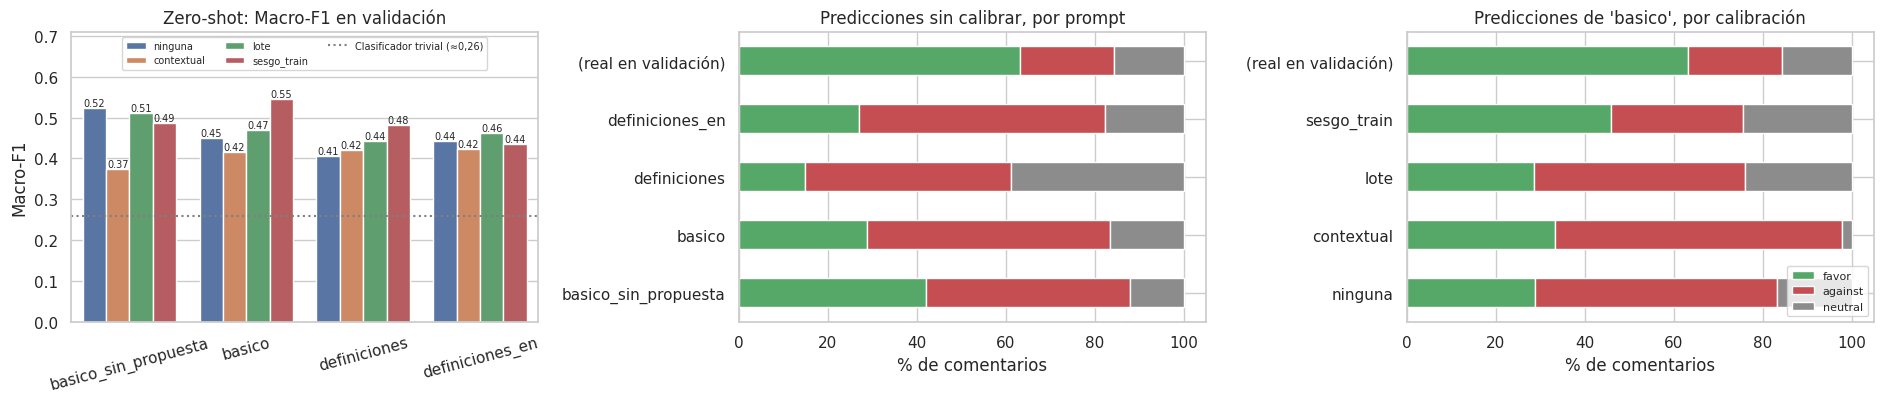

Mejor zero-shot: prompt 'basico' | calibración = sesgo_train → Macro-F1 (val) = 0.546


In [9]:
MEJOR_ZS = zs.loc[zs["macro_f1"].idxmax()]
PROMPT_ZS, CAL_ZS = MEJOR_ZS["experimento"], MEJOR_ZS["calibracion"]
DIST_REAL_VAL = (pd.Series(y_val).value_counts(normalize=True) * 100).reindex(CLASES).to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
sns.barplot(data=zs, x="experimento", y="macro_f1", hue="calibracion", hue_order=METODOS_CAL, ax=axes[0])
axes[0].axhline(0.26, ls=":", c="gray", label="Clasificador trivial (≈0,26)")
axes[0].set_ylim(0, zs["macro_f1"].max() * 1.3)
axes[0].set_title("Zero-shot: Macro-F1 en validación"); axes[0].set_xlabel(""); axes[0].set_ylabel("Macro-F1")
axes[0].tick_params(axis="x", rotation=15); axes[0].legend(fontsize=7, ncol=3, loc="upper center")
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt="%.2f", fontsize=7)

# Distribución de las predicciones sin calibrar, por prompt
dist = zs[zs["calibracion"] == "ninguna"].set_index("experimento")[COLS_DIST]
dist.columns = CLASES
dist.loc["(real en validación)"] = DIST_REAL_VAL
dist.plot.barh(stacked=True, ax=axes[1], color=["C2", "C3", "C7"], legend=False)
axes[1].set_xlabel("% de comentarios"); axes[1].set_ylabel("")
axes[1].set_title("Predicciones sin calibrar, por prompt")

# Distribución de las predicciones del mejor prompt, por método de calibración
dist = zs[zs["experimento"] == PROMPT_ZS].set_index("calibracion")[COLS_DIST]
dist.columns = CLASES
dist.loc["(real en validación)"] = DIST_REAL_VAL
dist.plot.barh(stacked=True, ax=axes[2], color=["C2", "C3", "C7"])
axes[2].set_xlabel("% de comentarios"); axes[2].set_ylabel("")
axes[2].set_title(f"Predicciones de '{PROMPT_ZS}', por calibración")
axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

print(f"Mejor zero-shot: prompt '{PROMPT_ZS}' | calibración = {CAL_ZS} → Macro-F1 (val) = {MEJOR_ZS['macro_f1']:.3f}")

**Observaciones**

- **El mejor prompt sin calibrar es el más simple y sin la propuesta** (`basico_sin_propuesta`, Macro-F1 val 0,523), con 7–12 puntos de ventaja sobre los otros tres (0,41–0,45). Al agregar el título, *favor* baja del 42% al 29% de las predicciones (real: 63%) y *against* sube del 46% al 54%. Muchos títulos están redactados en negativo ("STOP…", "Parar la construcción…", "Reprobación de…"): un comentario que critica lo mismo que critica la propuesta es *favor*, pero un modelo de 1,5B no resuelve esa relación y responde *contra* por el tono. Sin la propuesta, el modelo clasifica básicamente el **tono del comentario**.
- **Definiciones e idioma no ayudan.** `definiciones` es el peor prompt sin calibrar (0,407): el modelo usa *neutral* como comodín (39% de las predicciones contra 16% real) y casi no predice *favor* (15%). En inglés (0,442) queda a la par de `basico` (0,449). Las definiciones sí suben la masa de probabilidad en las etiquetas (0,79–0,83 → 0,90–0,94): el modelo respeta mejor el formato, pero no decide mejor.
- **Sesgo hacia *against*:** sin calibrar, todos los prompts predicen *favor* de menos (15–42% contra 63% real) y *against* de más (46–55% contra 21%).
- **`contextual` elimina *neutral*:** ante las entradas vacías el modelo responde *neutral* con probabilidad 0,98–1,00 (columnas `p_vacia_*`), así que la corrección multiplica *favor* y *against* por ≈100 y *neutral* queda en 0–5% de las predicciones. Empeora tres de los cuatro prompts.
- **`lote` ayuda poco** (+2 a +4 puntos en los prompts con propuesta, −1 en `basico_sin_propuesta`): sube *neutral* sin destruirla y baja algo *against*, pero *favor* sigue en 19–38%. Esta corrección empuja hacia una cantidad pareja de predicciones por clase, y con una distribución real de 63/21/16 eso no alcanza para recuperar *favor*.
- **`sesgo_train` cambia el ranking.** Con `basico` sube de 0,449 a **0,546** (+10 puntos, el mejor zero-shot): *favor* pasa del 29% al 46% de las predicciones y *against* del 54% al 30%. El sesgo ajustado para *against* es −4,0 (el borde de la grilla) en los tres prompts con propuesta: el modelo sobrepredice *against* tanto que se usa la máxima corrección permitida. Que el prompt con la propuesta quede primero al calibrar indica que su problema era, al menos en buena parte, un sesgo hacia *contra* y no falta de comprensión. La diferencia con el mejor sin calibrar es de 2 puntos, poco con ≈65 comentarios *neutral*.
- **Pero `sesgo_train` también es ruidoso:** empeora `basico_sin_propuesta` (0,523 → 0,486, con *neutral* sobrecorregida al 31%) y `definiciones_en` (0,442 → 0,436). Con 200 comentarios de ajuste (≈44 *against* y ≈31 *neutral*), el sesgo óptimo en train no siempre se traslada a validación.

### 4.5. Few-shot

Los ejemplos se agregan como turnos previos de la conversación (comentario del usuario → etiqueta del asistente), con la misma instrucción del zero-shot y en orden aleatorio. Los mismos ejemplos se usan para todos los comentarios de una corrida. Se toman de propuestas de train, que no aparecen en validación ni test (split agrupado), así que no hay filtración.

En una primera corrida el few-shot empeoraba al agregar ejemplos, y se identificaron dos causas posibles, que ahora se ponen a prueba:

1. **Prompt sin la propuesta:** el few-shot heredaba el mejor prompt del zero-shot, que no muestra la propuesta, y sin ella varios ejemplos quedan contradictorios (p. ej. *"La propuesta es bienvenida, pero…"* → `contra`). Se compara `basico_sin_propuesta` contra `basico` (el mismo prompt con el título de la propuesta). Los prompts con definiciones se descartan porque rindieron peor en zero-shot y son más largos.
2. **Ejemplos balanceados:** con 1/3 de ejemplos *neutral* el modelo copiaba esa proporción y predecía *neutral* para el 40–70% de los comentarios (real: 16%). Se compara la selección **balanceada** contra una **proporcional** a la distribución de clases de train (con al menos un ejemplo por clase).

**Diseño:**
- **4.5.1.** Con 6 ejemplos en total: prompt (`basico_sin_propuesta` / `basico`) × selección (balanceada 2/2/2 / proporcional 4/1/1) × 3 semillas.
- **4.5.2.** Con la mejor combinación de 4.5.1: 3, 6 y 12 ejemplos × 3 semillas. Con 3 ejemplos las dos selecciones coinciden (1/1/1).

In [10]:
SEEDS_DEMOS = [0, 1, 2]
PROMPTS_FS = ["basico_sin_propuesta", "basico"]
SELECCIONES = ["balanceada", "proporcional"]
N_BASE = 6
N_DEMOS = [3, 6, 12]
DIST_TRAIN = train_df["label"].value_counts(normalize=True).reindex(CLASES)

def cuotas(n, seleccion):
    """Cantidad de ejemplos por clase."""
    if seleccion == "balanceada":
        assert n % len(CLASES) == 0
        return {c: n // len(CLASES) for c in CLASES}
    # proporcional a train, por restos mayores, con al menos 1 ejemplo por clase
    ideal = DIST_TRAIN * n
    q = np.maximum(1, np.floor(ideal)).astype(int)
    while q.sum() < n:
        q[(ideal - q).idxmax()] += 1
    while q.sum() > n:
        q[(q - ideal).where(q > 1).idxmax()] -= 1
    return q.to_dict()

def elegir_demos(n, seleccion, seed):
    """Ejemplos al azar de train según las cuotas por clase, en orden aleatorio."""
    rng = np.random.RandomState(seed)
    q = cuotas(n, seleccion)
    demos = pd.concat([train_df[train_df["label"] == c].sample(q[c], random_state=rng) for c in CLASES])
    return demos.sample(frac=1, random_state=rng)

print("Distribución de train:", DIST_TRAIN.round(3).to_dict())
for n in N_DEMOS:
    print(f"n={n:2d} |", " | ".join(f"{s}: {cuotas(n, s)}" for s in SELECCIONES))

corridas_fs = set()

def correr_few_shot(prompt, seleccion, n, seed):
    if (prompt, seleccion, n, seed) in corridas_fs:   # ya corrido (p. ej. n=6 en 4.5.1)
        return
    salida = correr_config(prompt, val_df, elegir_demos(n, seleccion, seed))
    experimento = f"{prompt} | {seleccion} | n={n} | seed={seed}"
    registrar("few_shot", experimento, salida, y_val, prompt=prompt, seleccion=seleccion, n_demos=n, seed_demos=seed)
    corridas_fs.add((prompt, seleccion, n, seed))
    print(f"{experimento:45s} | {resumen_f1(salida, y_val)} | "
          f"{salida['costo']['tokens_prompt_medio']:.0f} tok/prompt | {salida['costo']['t_inf_s']:.0f} s")

def resumir(df):
    """Media y desvío entre semillas por configuración y método de calibración."""
    return (df.groupby(["prompt", "seleccion", "n_demos", "calibracion"], sort=False)
              .agg(macro_f1_media=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
                   **{f"f1_{c}": (f"f1_{c}", "mean") for c in CLASES},
                   **{f"%pred_{c}": (f"%pred_{c}", "mean") for c in CLASES},
                   masa_etiquetas=("masa_etiquetas", "mean"), tokens_prompt_medio=("tokens_prompt_medio", "mean"),
                   t_inf_por_1000_s=("t_inf_por_1000_s", "mean"), vram_pico_GB=("vram_pico_GB", "max"))
              .reset_index())

print("\nEjemplo de prompt few-shot (basico, proporcional, n=6):\n")
print(armar_prompt(PROMPTS["basico"], val_df.iloc[0], elegir_demos(N_BASE, "proporcional", 0)))

Distribución de train: {'favor': 0.625, 'against': 0.22, 'neutral': 0.155}
n= 3 | balanceada: {'favor': 1, 'against': 1, 'neutral': 1} | proporcional: {'favor': 1, 'against': 1, 'neutral': 1}
n= 6 | balanceada: {'favor': 2, 'against': 2, 'neutral': 2} | proporcional: {'favor': 4, 'against': 1, 'neutral': 1}
n=12 | balanceada: {'favor': 4, 'against': 4, 'neutral': 4} | proporcional: {'favor': 7, 'against': 3, 'neutral': 2}

Ejemplo de prompt few-shot (basico, proporcional, n=6):

<|im_start|>system
Tu tarea es clasificar la postura de comentarios escritos por ciudadanos sobre propuestas publicadas en una plataforma de participación ciudadana. Indicá si el comentario está a favor de la propuesta, en contra de la propuesta o es neutral.
Respondé con una sola palabra: favor, contra o neutral.<|im_end|>
<|im_start|>user
Propuesta: "Acabar con los excrementos de los perros en las calles."
Comentario: "Estoy completamente de acuerdo en que es necesario hacer algo para que los dueños se hagan 

#### 4.5.1. Propuesta y selección de ejemplos (6 ejemplos)

In [11]:
for prompt in PROMPTS_FS:
    for seleccion in SELECCIONES:
        for seed in SEEDS_DEMOS:
            correr_few_shot(prompt, seleccion, N_BASE, seed)

fs = pd.DataFrame([r for r in resultados if r["grupo"] == "few_shot"])
r451 = resumir(fs[fs["n_demos"] == N_BASE])
display(r451.set_index(["prompt", "seleccion", "calibracion"]).drop(columns="n_demos").round(3))

basico_sin_propuesta | balanceada | n=6 | seed=0 | ninguna=0.369 | contextual=0.410 | lote=0.423 | sesgo_train=0.516 | 820 tok/prompt | 62 s
basico_sin_propuesta | balanceada | n=6 | seed=1 | ninguna=0.407 | contextual=0.375 | lote=0.436 | sesgo_train=0.501 | 830 tok/prompt | 66 s
basico_sin_propuesta | balanceada | n=6 | seed=2 | ninguna=0.435 | contextual=0.383 | lote=0.458 | sesgo_train=0.474 | 805 tok/prompt | 66 s
basico_sin_propuesta | proporcional | n=6 | seed=0 | ninguna=0.393 | contextual=0.397 | lote=0.454 | sesgo_train=0.505 | 803 tok/prompt | 66 s
basico_sin_propuesta | proporcional | n=6 | seed=1 | ninguna=0.407 | contextual=0.396 | lote=0.464 | sesgo_train=0.553 | 665 tok/prompt | 55 s
basico_sin_propuesta | proporcional | n=6 | seed=2 | ninguna=0.454 | contextual=0.389 | lote=0.474 | sesgo_train=0.489 | 638 tok/prompt | 53 s
basico | balanceada | n=6 | seed=0            | ninguna=0.358 | contextual=0.388 | lote=0.415 | sesgo_train=0.527 | 935 tok/prompt | 79 s
basico | b

macro_f1_media  macro_f1_std  \
prompt               seleccion    calibracion                                 
basico_sin_propuesta balanceada   ninguna               0.404         0.033   
                                  contextual            0.389         0.018   
                                  lote                  0.439         0.018   
                                  sesgo_train           0.497         0.021   
                     proporcional ninguna               0.418         0.032   
                                  contextual            0.394         0.005   
                                  lote                  0.464         0.010   
                                  sesgo_train           0.516         0.033   
basico               balanceada   ninguna               0.394         0.038   
                                  contextual            0.382         0.010   
                                  lote                  0.439         0.027   
                                  sesgo_train           0.519         0.008   
                     proporcional ninguna               0.381         0.017   
                                  contextual            0.399         0.030   
                                  lote                  0.438         0.009   
                                  sesgo_train           0.547         0.009   

                                               f1_favor  f1_against  \
prompt               seleccion    calibracion                         
basico_sin_propuesta balanceada   ninguna         0.406       0.415   
                                  contextual      0.658       0.453   
                                  lote            0.476       0.426   
                                  sesgo_train     0.605       0.444   
                     proporcional ninguna         0.390       0.438   
                                  contextual      0.643       0.471   
                                  lote            0.492       0.456   
                                  sesgo_train     0.655       0.455   
basico               balanceada   ninguna         0.358       0.409   
                                  contextual      0.618       0.448   
                                  lote            0.463       0.425   
                                  sesgo_train     0.635       0.431   
                     proporcional ninguna         0.298       0.422   
                                  contextual      0.635       0.467   
                                  lote            0.438       0.433   
                                  sesgo_train     0.690       0.447   

                                               f1_neutral  %pred_favor  \
prompt               seleccion    calibracion                            
basico_sin_propuesta balanceada   ninguna           0.391       18.644   
                                  contextual        0.057       53.511   
                                  lote              0.415       23.890   
                                  sesgo_train       0.443       37.934   
                     proporcional ninguna           0.426       16.626   
                                  contextual        0.067       51.412   
                                  lote              0.444       24.939   
                                  sesgo_train       0.437       44.149   
basico               balanceada   ninguna           0.415       14.931   
                                  contextual        0.078       45.682   
                                  lote              0.431       21.711   
                                  sesgo_train       0.490       37.450   
                     proporcional ninguna           0.422       11.461   
                                  contextual        0.096       45.440   
                                  lote              0.444       19.370   
                                  sesgo_train       0.505       43.906   

            

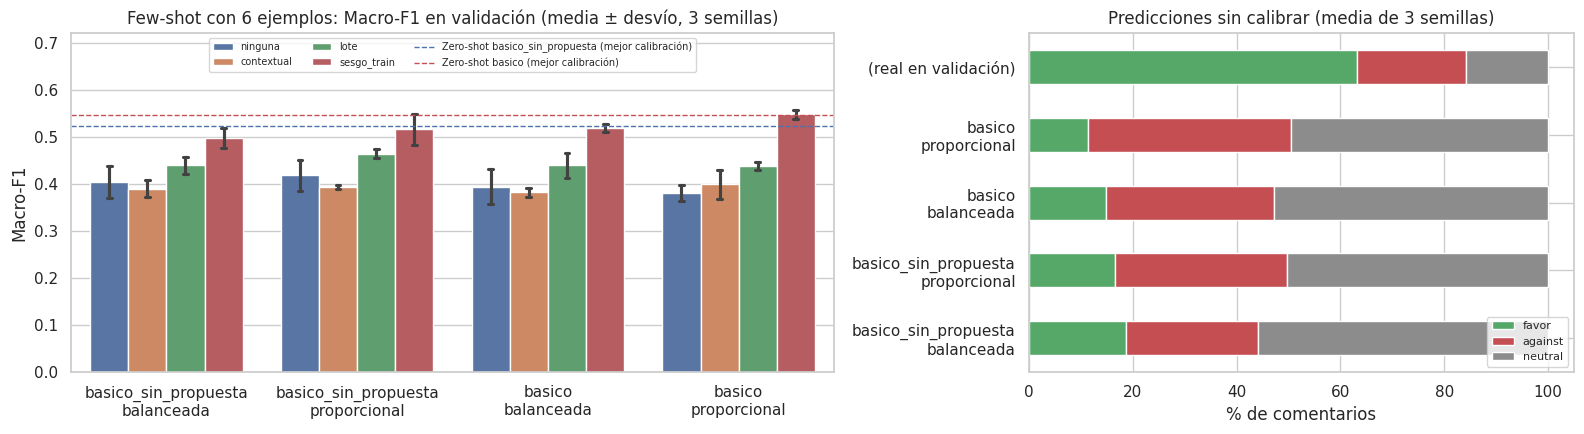

Mejor combinación con 6 ejemplos: prompt 'basico' | selección proporcional | calibración sesgo_train → Macro-F1 (val) = 0.547 ± 0.009


In [12]:
fs6 = fs[fs["n_demos"] == N_BASE].assign(config=lambda d: d["prompt"] + "\n" + d["seleccion"])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
sns.barplot(data=fs6, x="config", y="macro_f1", hue="calibracion", hue_order=METODOS_CAL,
            errorbar="sd", capsize=0.1, ax=axes[0])
for p in PROMPTS_FS:
    ref = zs[(zs["experimento"] == p)]["macro_f1"].max()
    axes[0].axhline(ref, ls="--", lw=1, c="C0" if p == "basico_sin_propuesta" else "C3",
                    label=f"Zero-shot {p} (mejor calibración)")
axes[0].set_ylim(0, fs6["macro_f1"].max() * 1.3)
axes[0].set_title(f"Few-shot con {N_BASE} ejemplos: Macro-F1 en validación (media ± desvío, 3 semillas)")
axes[0].set_xlabel(""); axes[0].set_ylabel("Macro-F1"); axes[0].legend(fontsize=7, ncol=3, loc="upper center")

dist = (fs6[fs6["calibracion"] == "ninguna"].groupby("config", sort=False)[COLS_DIST].mean())
dist.columns = CLASES
dist.loc["(real en validación)"] = DIST_REAL_VAL
dist.plot.barh(stacked=True, ax=axes[1], color=["C2", "C3", "C7"])
axes[1].set_xlabel("% de comentarios"); axes[1].set_ylabel("")
axes[1].set_title("Predicciones sin calibrar (media de 3 semillas)"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

mejor = r451.loc[r451["macro_f1_media"].idxmax()]
PROMPT_FS, SEL_FS = mejor["prompt"], mejor["seleccion"]
print(f"Mejor combinación con {N_BASE} ejemplos: prompt '{PROMPT_FS}' | selección {SEL_FS} | "
      f"calibración {mejor['calibracion']} → Macro-F1 (val) = {mejor['macro_f1_media']:.3f} ± {mejor['macro_f1_std']:.3f}")

**Observaciones**

- **Selección:** la hipótesis de que el modelo copiaba la proporción de clases de los ejemplos **no se confirma**. Sin calibrar, con ejemplos proporcionales (solo 1 *neutral* de 6) el modelo igual predice *neutral* para el 50% de los comentarios, contra 53–56% con ejemplos balanceados (real: 16%). En zero-shot el mismo prompt predecía *neutral* el 17% de las veces. Basta con agregar ejemplos para que el modelo se vuelva "cauto": *favor* cae al 11–19% de las predicciones.
- **Propuesta:** sin calibrar casi no cambia nada (0,38–0,42 en los cuatro casos, todos por debajo del zero-shot). Con `sesgo_train`, mostrar la propuesta ayuda 2–3 puntos (0,519 / 0,547 contra 0,497 / 0,516), igual que en zero-shot.
- **Calibración:** `sesgo_train` es lo que hace útil al few-shot (+9 a +17 puntos respecto de sin calibrar). Baja *neutral* al 24–28% de las predicciones y sube *favor* al 37–44%. `lote` suma 3–6 puntos, pero se queda en 0,44–0,46, y `contextual` vuelve a eliminar *neutral* (<1% de las predicciones). Ya calibrados, la selección proporcional supera a la balanceada (0,547 ± 0,009 contra 0,519 ± 0,008 con `basico`).
- **La corrección de *neutral* está en el límite:** el sesgo ajustado para *neutral* es −3,4 a −4,0 en las 12 corridas, contra el borde de la grilla en −4. Aun así se sigue prediciendo *neutral* para el 24–28% de los comentarios. Con una grilla más amplia, el few-shot calibrado probablemente rendiría algo más.
- **Variabilidad:** el desvío entre semillas (0,01–0,04) es del orden de las diferencias entre combinaciones. Además, el sesgo ajustado para *against* va de +1,9 a −4,0 según qué ejemplos tocaron.
- **Contra el zero-shot:** la mejor combinación con 6 ejemplos (`basico`, proporcional, `sesgo_train`: 0,547 ± 0,009) empata con el mejor zero-shot (0,546), pero con 4 veces más tokens por prompt (819 contra 188) y 5 veces más tiempo de inferencia.

#### 4.5.2. Cantidad de ejemplos

Con la mejor combinación de prompt y selección se varía la cantidad total de ejemplos. El punto *n* = 0 es el zero-shot con el mismo prompt.

In [13]:
for n in N_DEMOS:
    for seed in SEEDS_DEMOS:
        correr_few_shot(PROMPT_FS, SEL_FS, n, seed)

fs = pd.DataFrame([r for r in resultados if r["grupo"] == "few_shot"])
zs_ref = zs[zs["experimento"] == PROMPT_FS].assign(seleccion=SEL_FS, n_demos=0)
r452 = resumir(pd.concat([zs_ref, fs[(fs["prompt"] == PROMPT_FS) & (fs["seleccion"] == SEL_FS)]]))
r452 = r452.sort_values(["n_demos", "calibracion"], key=lambda s: s.map(METODOS_CAL.index) if s.name == "calibracion" else s)
display(r452.set_index(["n_demos", "calibracion"]).drop(columns=["prompt", "seleccion"]).round(3))

fila = r452[r452["n_demos"] > 0].sort_values("macro_f1_media", ascending=False).iloc[0]
N_FINAL, CAL_FS = int(fila["n_demos"]), fila["calibracion"]

basico | proporcional | n=3 | seed=0          | ninguna=0.363 | contextual=0.360 | lote=0.424 | sesgo_train=0.511 | 571 tok/prompt | 47 s
basico | proporcional | n=3 | seed=1          | ninguna=0.398 | contextual=0.412 | lote=0.433 | sesgo_train=0.513 | 471 tok/prompt | 39 s
basico | proporcional | n=3 | seed=2          | ninguna=0.427 | contextual=0.380 | lote=0.452 | sesgo_train=0.537 | 477 tok/prompt | 39 s
basico | proporcional | n=12 | seed=0         | ninguna=0.408 | contextual=0.438 | lote=0.452 | sesgo_train=0.585 | 1625 tok/prompt | 147 s
basico | proporcional | n=12 | seed=1         | ninguna=0.446 | contextual=0.378 | lote=0.472 | sesgo_train=0.558 | 1680 tok/prompt | 152 s
basico | proporcional | n=12 | seed=2         | ninguna=0.346 | contextual=0.390 | lote=0.455 | sesgo_train=0.533 | 1801 tok/prompt | 163 s


macro_f1_media  macro_f1_std  f1_favor  f1_against  \
n_demos calibracion                                                       
0       ninguna               0.449           NaN     0.542       0.462   
        contextual            0.416           NaN     0.581       0.476   
        lote                  0.469           NaN     0.533       0.459   
        sesgo_train           0.546           NaN     0.705       0.488   
3       ninguna               0.396         0.032     0.351       0.413   
        contextual            0.384         0.026     0.590       0.457   
        lote                  0.436         0.014     0.439       0.422   
        sesgo_train           0.520         0.014     0.643       0.447   
6       ninguna               0.381         0.017     0.298       0.422   
        contextual            0.399         0.030     0.635       0.467   
        lote                  0.438         0.009     0.438       0.433   
        sesgo_train           0.547         0.009     0.690       0.447   
12      ninguna               0.400         0.051     0.384       0.410   
        contextual            0.402         0.032     0.686       0.462   
        lote                  0.460         0.011     0.508       0.424   
        sesgo_train           0.559         0.026     0.733       0.440   

                     f1_neutral  %pred_favor  %pred_against  %pred_neutral  \
n_demos calibracion                                                          
0       ninguna           0.343       28.814         54.479         16.707   
        contextual        0.189       33.414         64.407          2.179   
        lote              0.415       28.571         47.458         23.971   
        sesgo_train       0.446       46.005         29.540         24.455   
3       ninguna           0.424       14.447         39.225         46.328   
        contextual        0.105       38.579         60.452          0.969   
        lote              0.448       19.693         39.790         40.517   
        sesgo_train       0.472       39.467         36.400         24.132   
6       ninguna           0.422       11.461         38.983         49.556   
        contextual        0.096       45.440         53.753          0.807   
        lote              0.444       19.370         38.499         42.131   
        sesgo_train       0.505       43.906         29.944         26.150   
12      ninguna           0.405       16.384         28.006         55.609   
        contextual        0.059       58.031         41.485          0.484   
        lote              0.447       24.052         31.396         44.552   
        sesgo_train       0.504       52.623         24.374         23.002   

                     masa_etiquetas  tokens_prompt_medio  t_inf_por_1000_s  \
n_demos calibracion                                                          
0       ninguna               0.828              188.487            30.340   
        contextual            0.828              188.487            30.340   
        lote                  0.828              188.487            30.340   
        sesgo_train           0.828              188.487            30.340   
3       ninguna               0.861              506.820           100.268   
        contextual            0.861              506.820           100.268   
        lote                  0.861              506.820           100.268   
        sesgo_train           0.861              506.820           100.268   
6       ninguna               0.926              819.487           164.734   
        contextual            0.926              819.487           164.734   
        lote                  0.926              819.487           164.734   
        sesgo_train           0.926              819.487           164.734   
12      ninguna               0.959             1702.487           372.014   
        contextual            0.959             1702.487           372.014   
        lote     

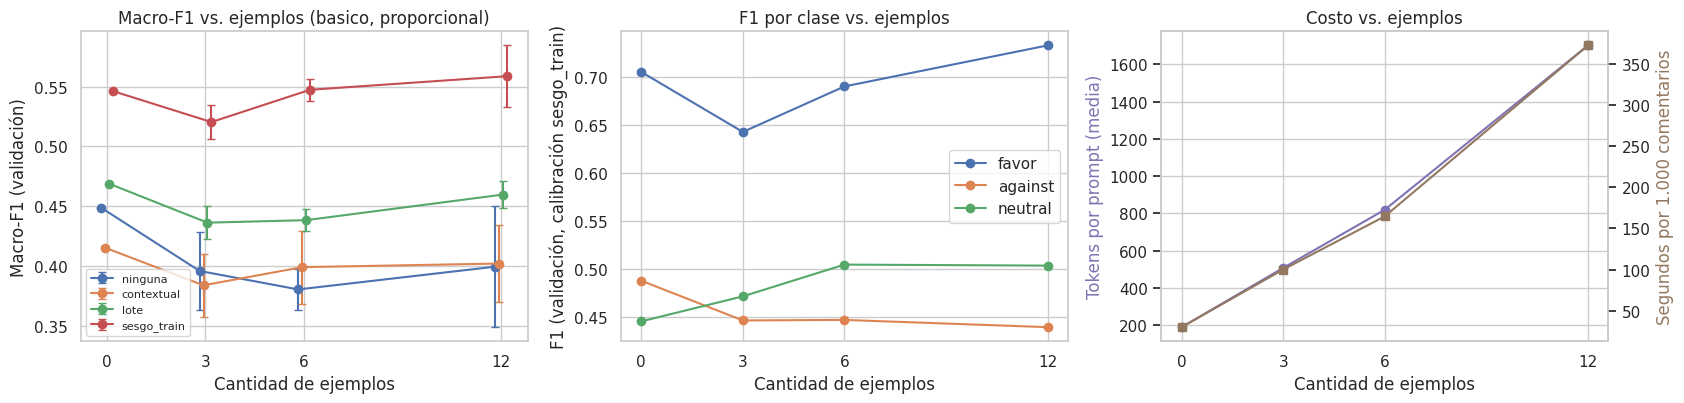

Mejor few-shot: prompt 'basico' | selección proporcional | n=12 | calibración sesgo_train → Macro-F1 (val) = 0.559 ± 0.026


,p_vacia_favor,p_vacia_against,p_vacia_neutral,p_lote_favor,p_lote_against,p_lote_neutral,sesgo_favor,sesgo_against,sesgo_neutral
basico_sin_propuesta | balanceada | n=6 | seed=0,0.0,0.000,1.000,0.121,0.279,0.601,0.0,-2.4,-3.9
basico_sin_propuesta | balanceada | n=6 | seed=1,0.0,0.000,1.000,0.237,0.200,0.563,0.0,-1.8,-3.6
basico_sin_propuesta | balanceada | n=6 | seed=2,0.0,0.000,1.000,0.227,0.276,0.497,0.0,1.9,-3.7
basico_sin_propuesta | proporcional | n=6 | seed=0,0.0,0.000,1.000,0.148,0.317,0.535,0.0,-3.8,-3.4
basico_sin_propuesta | proporcional | n=6 | seed=1,0.0,0.000,1.000,0.197,0.296,0.506,0.0,-4.0,-3.8
basico_sin_propuesta | proporcional | n=6 | seed=2,0.0,0.000,1.000,0.218,0.354,0.428,0.0,0.1,-3.9
basico | balanceada | n=6 | seed=0,0.0,0.000,0.999,0.114,0.376,0.510,0.0,-4.0,-3.9
basico | balanceada | n=6 | seed=1,0.0,0.000,1.000,0.227,0.261,0.511,0.0,-0.2,-2.4
basico | balanceada | n=6 | seed=2,0.0,0.000,1.000,0.155,0.319,0.525,0.0,-2.1,-4.0
basico | proporcional | n=6 | seed=0,0.0,0.000,1.000,0.135,0.416,0.449,0.0,-4.0,-3.9


In [14]:
xs = [0] + N_DEMOS
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for i, m in enumerate(METODOS_CAL):
    g = r452[r452["calibracion"] == m]
    axes[0].errorbar(g["n_demos"] + (i - 1.5) * 0.12, g["macro_f1_media"], yerr=g["macro_f1_std"].fillna(0),
                     fmt="o-", capsize=3, label=m)
axes[0].set_xlabel("Cantidad de ejemplos"); axes[0].set_ylabel("Macro-F1 (validación)")
axes[0].set_title(f"Macro-F1 vs. ejemplos ({PROMPT_FS}, {SEL_FS})"); axes[0].set_xticks(xs); axes[0].legend(fontsize=8)

g = r452[r452["calibracion"] == CAL_FS]
for c in CLASES:
    axes[1].plot(g["n_demos"], g[f"f1_{c}"], marker="o", label=c)
axes[1].set_xlabel("Cantidad de ejemplos"); axes[1].set_ylabel(f"F1 (validación, calibración {CAL_FS})")
axes[1].set_title("F1 por clase vs. ejemplos"); axes[1].set_xticks(xs); axes[1].legend()

g = r452[r452["calibracion"] == "ninguna"]
axes[2].plot(g["n_demos"], g["tokens_prompt_medio"], marker="o", c="C4")
axes[2].set_xlabel("Cantidad de ejemplos"); axes[2].set_ylabel("Tokens por prompt (media)", color="C4")
ax2 = axes[2].twinx()
ax2.plot(g["n_demos"], g["t_inf_por_1000_s"], marker="s", c="C5")
ax2.set_ylabel("Segundos por 1.000 comentarios", color="C5"); ax2.grid(False)
axes[2].set_title("Costo vs. ejemplos"); axes[2].set_xticks(xs)
plt.tight_layout(); plt.show()

print(f"Mejor few-shot: prompt '{PROMPT_FS}' | selección {SEL_FS} | n={N_FINAL} | calibración {CAL_FS} → "
      f"Macro-F1 (val) = {fila['macro_f1_media']:.3f} ± {fila['macro_f1_std']:.3f}")
display(tabla_ajustes("few_shot").round(3))

**Observaciones**

- **Sin calibrar, los ejemplos no ayudan con ninguna cantidad:** 0,449 (zero-shot) → 0,396 / 0,381 / 0,400 con 3 / 6 / 12 ejemplos. **Con `sesgo_train`, el few-shot recién empata con el zero-shot a partir de 6 ejemplos:** 0,546 → 0,520 / 0,547 / 0,559. La mejora con 12 ejemplos (+1,3 puntos) es menor que el desvío entre semillas (0,026).
- **Los ejemplos enseñan el formato, no la tarea:** la masa de probabilidad en las etiquetas sube en forma monótona (0,83 → 0,86 → 0,93 → 0,96), pero el Macro-F1 casi no se mueve.
- **Variabilidad:** el desvío entre semillas no baja con más ejemplos (0,014 / 0,009 / 0,026 con `sesgo_train`, y 0,032 / 0,017 / 0,051 sin calibrar). Con 12 ejemplos sigue importando mucho cuáles tocaron.
- **Por clase** (con `sesgo_train`): más ejemplos mejoran *favor* (F1 0,64 → 0,69 → 0,73) y algo *neutral* (0,47 → 0,51 → 0,50). *Against* no mejora (0,45 → 0,45 → 0,44) y queda por debajo del zero-shot (0,49).
- **Costo:** el tiempo crece en forma lineal con los tokens del prompt (188 → 507 → 819 → 1.702 tokens; 30 → 100 → 165 → 372 s cada 1.000 comentarios). Con 12 ejemplos, la inferencia cuesta 12 veces más que el zero-shot por una mejora que no es significativa. El criterio de elegir el máximo en validación se queda con 12 ejemplos, aunque 6 ejemplos rinden lo mismo dentro del ruido a la mitad del costo.

### 4.6. Resumen de los experimentos en validación

Macro-F1 en validación de cada configuración (media de las 3 semillas en few-shot) con cada método de calibración.

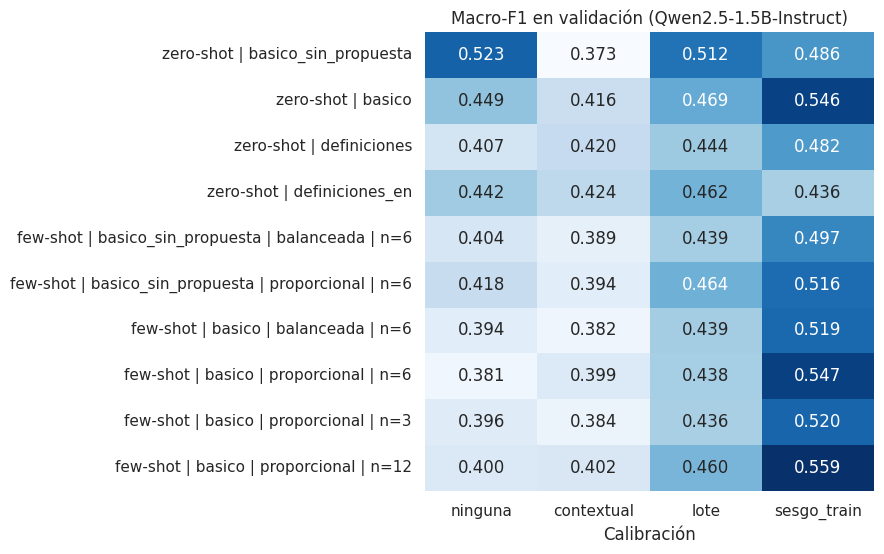

Configuración final zero-shot: {'prompt': 'basico', 'calibracion': 'sesgo_train'} → Macro-F1 (val) = 0.546
Configuración final few-shot: {'prompt': 'basico', 'seleccion': 'proporcional', 'n_demos': 12, 'calibracion': 'sesgo_train'} | semillas: [0, 1, 2] → Macro-F1 (val) = 0.559 ± 0.026


In [15]:
res_val = pd.DataFrame(resultados)
res_val["config"] = np.where(res_val["grupo"] == "zero_shot",
                             "zero-shot | " + res_val["prompt"],
                             "few-shot | " + res_val["prompt"] + " | " + res_val["seleccion"] +
                             " | n=" + res_val["n_demos"].astype(str))
piv = res_val.groupby(["config", "calibracion"], sort=False)["macro_f1"].mean().unstack()[METODOS_CAL]

fig, ax = plt.subplots(figsize=(9, 0.42 * len(piv) + 1.5))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=ax)
ax.set_xlabel("Calibración"); ax.set_ylabel("")
ax.set_title("Macro-F1 en validación (Qwen2.5-1.5B-Instruct)")
plt.tight_layout(); plt.show()

CONFIG_ZS = {"prompt": PROMPT_ZS, "calibracion": CAL_ZS}
CONFIG_FS = {"prompt": PROMPT_FS, "seleccion": SEL_FS, "n_demos": N_FINAL, "calibracion": CAL_FS}
print("Configuración final zero-shot:", CONFIG_ZS, f"→ Macro-F1 (val) = {MEJOR_ZS['macro_f1']:.3f}")
print("Configuración final few-shot:", CONFIG_FS, "| semillas:", SEEDS_DEMOS,
      f"→ Macro-F1 (val) = {fila['macro_f1_media']:.3f} ± {fila['macro_f1_std']:.3f}")

### 4.7. Evaluación final en test

Recién ahora se usa el conjunto de test, una única vez, para:
1. **Zero-shot:** el mejor prompt y método de calibración elegidos en 4.4.
2. **Few-shot:** la mejor configuración de 4.5 (prompt, selección, cantidad de ejemplos y calibración), con las **mismas 3 selecciones de ejemplos** (semillas 0, 1 y 2). Se reportan la media y el desvío.

No hay fine-tuning. El costo de "entrenamiento" es solo el ajuste de la calibración cuando corresponde (puntuar 200 comentarios de train para `sesgo_train`). Si la calibración elegida es `lote`, el sesgo se estima con los comentarios de test (sin sus etiquetas).

Como cada pasada calcula todas las calibraciones a la vez, al final se muestra también cómo habrían dado los otros métodos en test. Es solo informativo: la elección ya se hizo en validación.

In [16]:
res_test, preds_test, res_test_cal = [], {}, []

def evaluar_en_test(nombre, enfoque, prompt, calibracion, demos=None, **extra):
    salida = correr_config(prompt, test_df, demos)
    y_pred = salida["pred"][calibracion]
    preds_test[nombre] = y_pred
    res_test.append({"modelo": nombre, **metricas(y_test, y_pred), **distribucion(y_pred),
                     "t_train_s": salida["costo"]["t_ajuste_s"] if calibracion == "sesgo_train" else 0.0,
                     **salida["costo"], "tamaño_modelo_MB": TAMAÑO_LLM_MB, **extra})
    for m in METODOS_CAL:
        res_test_cal.append({"enfoque": enfoque, "modelo": nombre, "calibracion": m,
                             "elegida": m == calibracion, **metricas(y_test, salida["pred"][m])})
    print(nombre, f"→ Macro-F1 test = {res_test[-1]['macro_f1']:.3f} | {salida['costo']['t_inf_s']:.1f} s")

NOMBRE_ZS = f"Qwen2.5-1.5B zero-shot ({PROMPT_ZS}, cal. {CAL_ZS})"
evaluar_en_test(NOMBRE_ZS, "zero-shot", PROMPT_ZS, CAL_ZS, seed_demos=np.nan)

PREFIJO_FS = f"Qwen2.5-1.5B few-shot n={N_FINAL}"
for seed in SEEDS_DEMOS:
    evaluar_en_test(f"{PREFIJO_FS} (seed={seed})", "few-shot", PROMPT_FS, CAL_FS,
                    elegir_demos(N_FINAL, SEL_FS, seed), seed_demos=seed)

Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train) → Macro-F1 test = 0.537 | 15.6 s
Qwen2.5-1.5B few-shot n=12 (seed=0) → Macro-F1 test = 0.550 | 147.5 s
Qwen2.5-1.5B few-shot n=12 (seed=1) → Macro-F1 test = 0.524 | 152.4 s
Qwen2.5-1.5B few-shot n=12 (seed=2) → Macro-F1 test = 0.516 | 165.9 s


In [17]:
test_tabla = pd.DataFrame(res_test).set_index("modelo")
fs_test = test_tabla[test_tabla.index.str.startswith(PREFIJO_FS)]
fila_media, fila_std = fs_test.mean(numeric_only=True), fs_test.std(numeric_only=True)
NOMBRE_FS_MEDIA = f"{PREFIJO_FS} (media de 3 selecciones)"
NOMBRE_FS_STD = f"{PREFIJO_FS} (desvío entre selecciones)"
test_tabla.loc[NOMBRE_FS_MEDIA] = fila_media
test_tabla.loc[NOMBRE_FS_STD] = fila_std
test_tabla.loc[[NOMBRE_FS_MEDIA, NOMBRE_FS_STD], "seed_demos"] = np.nan

display(test_tabla.drop(columns="seed_demos")[COLS_METRICAS + COLS_DIST +
        ["tokens_prompt_medio", "masa_etiquetas", "t_train_s", "t_inf_s", "t_inf_por_1000_s",
         "vram_pico_GB", "tamaño_modelo_MB"]].round(3))
print(f"Few-shot ({PROMPT_FS}, {SEL_FS}, n={N_FINAL}, cal. {CAL_FS}): "
      f"Macro-F1 test = {fila_media['macro_f1']:.3f} ± {fila_std['macro_f1']:.3f} | "
      f"zero-shot ({PROMPT_ZS}, cal. {CAL_ZS}): {test_tabla.loc[NOMBRE_ZS, 'macro_f1']:.3f}")

print("\nEfecto de la calibración en test (informativo; la elección se hizo en validación, marcada con *):")
cal_test = (pd.DataFrame(res_test_cal).groupby(["enfoque", "calibracion"], sort=False)
            .agg(macro_f1=("macro_f1", "mean"), elegida=("elegida", "any")).reset_index())
cal_test["calibracion"] = cal_test["calibracion"] + np.where(cal_test["elegida"], " *", "")
display(cal_test.pivot(index="enfoque", columns="calibracion", values="macro_f1").round(3))

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,%pred_favor,%pred_against,%pred_neutral,tokens_prompt_medio,masa_etiquetas,t_train_s,t_inf_s,t_inf_por_1000_s,vram_pico_GB,tamaño_modelo_MB
modelo,,,,,,,,,,,,,,,
"Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",0.537,0.600,0.721,0.485,0.405,50.718,23.684,25.598,186.904,0.828,8.245,15.565,37.237,4.727,3087.429
Qwen2.5-1.5B few-shot n=12 (seed=0),0.550,0.617,0.728,0.500,0.422,54.785,21.292,23.923,1623.904,0.966,71.441,147.535,352.955,4.728,3087.429
Qwen2.5-1.5B few-shot n=12 (seed=1),0.524,0.617,0.751,0.443,0.377,59.569,19.378,21.053,1678.904,0.960,73.710,152.433,364.673,4.733,3087.429
Qwen2.5-1.5B few-shot n=12 (seed=2),0.516,0.565,0.670,0.500,0.377,44.976,28.947,26.077,1799.904,0.949,81.011,165.943,396.993,4.731,3087.429
Qwen2.5-1.5B few-shot n=12 (media de 3 selecciones),0.530,0.600,0.716,0.481,0.392,53.110,23.206,23.684,1700.904,0.959,75.388,155.304,371.540,4.730,3087.429
Qwen2.5-1.5B few-shot n=12 (desvío entre selecciones),0.018,0.030,0.042,0.033,0.026,7.439,5.064,2.520,90.039,0.008,5.000,9.534,22.808,0.003,0.000


Few-shot (basico, proporcional, n=12, cal. sesgo_train): Macro-F1 test = 0.530 ± 0.018 | zero-shot (basico, cal. sesgo_train): 0.537

Efecto de la calibración en test (informativo; la elección se hizo en validación, marcada con *):


calibracion,contextual,lote,ninguna,sesgo_train *
enfoque,,,,
few-shot,0.407,0.460,0.391,0.530
zero-shot,0.363,0.468,0.474,0.537


**Observaciones**

- **El test confirma lo visto en validación:** zero-shot 0,546 → 0,537 y few-shot 0,559 ± 0,026 → 0,530 ± 0,018. El few-shot cae más, algo esperable, porque se eligió entre muchas más configuraciones (más sesgo de selección).
- **El few-shot no supera al zero-shot en test** (0,530 ± 0,018 contra 0,537). Solo una de las tres selecciones de ejemplos (semilla 0: 0,550) queda por encima, y la diferencia entre la mejor y la peor (0,550 y 0,516) es mayor que la diferencia entre enfoques.
- **El ranking de calibraciones se mantiene:** `sesgo_train` es la mejor en los dos enfoques (+6 puntos sobre sin calibrar en zero-shot y +14 en few-shot). `lote` queda en 0,46–0,47 y `contextual` es la peor en zero-shot (0,363).
- **Costos:** el zero-shot tarda 37 s cada 1.000 comentarios en una T4 (30 s en validación) y el few-shot con 12 ejemplos, 372 s. Ajustar la calibración (puntuar las entradas vacías y los 200 comentarios de train) cuesta 8 s en zero-shot y 75 s en few-shot. Es el único "entrenamiento" del enfoque y es comparable al fine-tuning de BETO (72 s).

### 4.8. Análisis de resultados

#### 4.8.1. Matrices de confusión y F1 por clase

Para el few-shot se muestra la selección de ejemplos con Macro-F1 de validación más cercano a la mediana (la elección no usa el test).

Selección de ejemplos representativa: seed 1


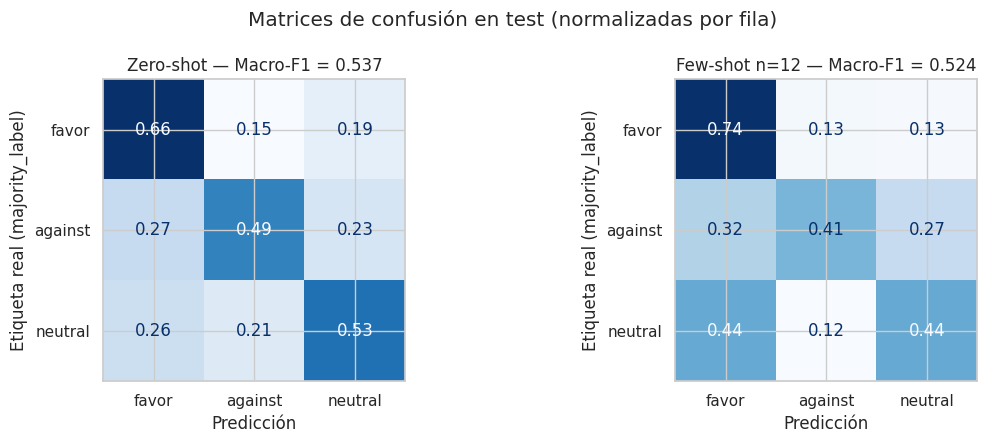

=== Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train) ===
              precision    recall  f1-score   support

       favor      0.797     0.658     0.721       257
     against      0.475     0.495     0.485        95
     neutral      0.327     0.530     0.405        66

    accuracy                          0.600       418
   macro avg      0.533     0.561     0.537       418
weighted avg      0.650     0.600     0.617       418

=== Qwen2.5-1.5B few-shot n=12 (seed=1) ===
              precision    recall  f1-score   support

       favor      0.763     0.739     0.751       257
     against      0.481     0.411     0.443        95
     neutral      0.330     0.439     0.377        66

    accuracy                          0.617       418
   macro avg      0.525     0.530     0.524       418
weighted avg      0.631     0.617     0.622       418



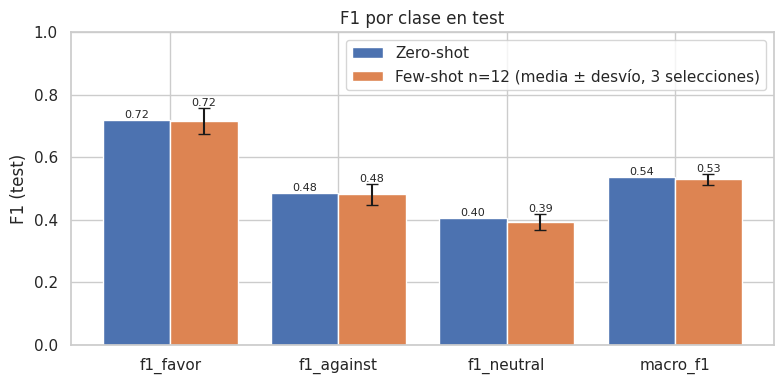

In [18]:
fs_val_final = fs[(fs["prompt"] == PROMPT_FS) & (fs["seleccion"] == SEL_FS) &
                  (fs["n_demos"] == N_FINAL) & (fs["calibracion"] == CAL_FS)]
seed_rep = int(fs_val_final.iloc[(fs_val_final["macro_f1"] - fs_val_final["macro_f1"].median()).abs().argmin()]["seed_demos"])
NOMBRE_FS = f"{PREFIJO_FS} (seed={seed_rep})"
print("Selección de ejemplos representativa: seed", seed_rep)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (titulo, nombre) in zip(axes, [("Zero-shot", NOMBRE_ZS), (f"Few-shot n={N_FINAL}", NOMBRE_FS)]):
    y_pred = preds_test[nombre]
    cm = confusion_matrix(y_test, y_pred, labels=CLASES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{titulo} — Macro-F1 = {f1_score(y_test, y_pred, average='macro'):.3f}")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Etiqueta real (majority_label)")
plt.suptitle("Matrices de confusión en test (normalizadas por fila)"); plt.tight_layout(); plt.show()

for nombre in [NOMBRE_ZS, NOMBRE_FS]:
    print(f"=== {nombre} ===")
    print(classification_report(y_test, preds_test[nombre], labels=CLASES, digits=3))

cols_f1 = [f"f1_{c}" for c in CLASES] + ["macro_f1"]
x = np.arange(len(cols_f1))
fig, ax = plt.subplots(figsize=(8, 4))
b_zs = ax.bar(x - 0.2, test_tabla.loc[NOMBRE_ZS, cols_f1].to_numpy(dtype=float), 0.4, label="Zero-shot")
b_fs = ax.bar(x + 0.2, fila_media[cols_f1].to_numpy(dtype=float), 0.4,
              yerr=fila_std[cols_f1].to_numpy(dtype=float), capsize=4,
              label=f"Few-shot n={N_FINAL} (media ± desvío, 3 selecciones)")
ax.bar_label(b_zs, fmt="%.2f", fontsize=8); ax.bar_label(b_fs, fmt="%.2f", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(cols_f1)
ax.set_ylabel("F1 (test)"); ax.set_title("F1 por clase en test"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.show()

**Observaciones**

- **La calibración corrige la confusión dominante sin calibrar.** En la corrida anterior, el zero-shot sin calibrar mandaba el 37% de *favor* a *against*; con `sesgo_train` ese error baja al 15% (38 de 257). Ahora los errores sobre *favor* se reparten entre *against* (15%) y *neutral* (19%).
- ***Against* se confunde para los dos lados:** el zero-shot acierta el 49% de los *against* y manda un 27% a *favor* y un 23% a *neutral*. El few-shot (semilla 1) acierta solo el 41%.
- ***Neutral* sigue siendo la clase más difícil:** el recall es aceptable (53% en zero-shot y 44% en few-shot), pero la precisión es de apenas 0,33, porque se predice *neutral* para el 21–26% de los comentarios cuando el real es 16%.
- **Zero-shot contra few-shot:** el few-shot es mejor en *favor* (F1 0,751 contra 0,721, por menos *favor* → *neutral*) y peor en *against* (0,443 contra 0,485) y *neutral* (0,377 contra 0,405). Por eso el Macro-F1 termina más bajo.

#### 4.8.2. Desempeño según el acuerdo entre anotadores

Si el LLM falla sobre todo en los comentarios donde los anotadores tampoco coincidieron, parte del error se explica por la ambigüedad de las etiquetas (techo de desempeño discutido en la parte 1).

In [19]:
filas = []
for nombre in [NOMBRE_ZS, NOMBRE_FS]:
    for nivel in ["Total (3/3)", "Parcial (2/3)"]:
        m = (test_df["nivel_acuerdo"] == nivel).to_numpy()
        filas.append({"modelo": nombre, "nivel_acuerdo": nivel, "n": m.sum(),
                      "accuracy": accuracy_score(y_test[m], preds_test[nombre][m]),
                      "macro_f1": f1_score(y_test[m], preds_test[nombre][m], labels=CLASES,
                                           average="macro", zero_division=0)})
display(pd.DataFrame(filas).set_index(["modelo", "nivel_acuerdo"]).round(3))

n  \
modelo                                            nivel_acuerdo        
Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train) Total (3/3)    216   
                                                  Parcial (2/3)  202   
Qwen2.5-1.5B few-shot n=12 (seed=1)               Total (3/3)    216   
                                                  Parcial (2/3)  202   

                                                                 accuracy  \
modelo                                            nivel_acuerdo             
Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train) Total (3/3)       0.681   
                                                  Parcial (2/3)     0.515   
Qwen2.5-1.5B few-shot n=12 (seed=1)               Total (3/3)       0.713   
                                                  Parcial (2/3)     0.515   

                                                                 macro_f1  
modelo                                            nivel_acuerdo            
Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train) Total (3/3)       0.515  
                                                  Parcial (2/3)     0.508  
Qwen2.5-1.5B few-shot n=12 (seed=1)               Total (3/3)       0.522  
                                                  Parcial (2/3)     0.490

**Observaciones**

- En los comentarios con acuerdo parcial (2/3), la accuracy cae entre 17 y 20 puntos (0,68 → 0,52 en zero-shot y 0,71 → 0,52 en few-shot). El 61% de los errores del few-shot (98 de 160) está en comentarios con acuerdo parcial, que son el 48% del test.
- El Macro-F1 casi no cambia entre subconjuntos (0,515 / 0,508 en zero-shot), porque las clases se reparten distinto en cada subconjunto. Solo el 25% de los *neutral* del corpus tiene acuerdo total (parte 1), así que en ese subconjunto hay muy pocos *neutral* y cada error pesa mucho en su F1. El subconjunto con acuerdo parcial es más equilibrado, lo que favorece al Macro-F1 aunque la accuracy sea menor.
- Incluso con acuerdo total, el Macro-F1 no pasa de 0,52. Parte del error se explica por la ambigüedad de las etiquetas, pero el modelo también falla en casos claros.

#### 4.8.3. Ejemplos de errores

Se muestran errores del modelo (zero-shot o few-shot) con mejor Macro-F1 en validación.

In [20]:
NOMBRE_ERR = NOMBRE_ZS if MEJOR_ZS["macro_f1"] >= fila["macro_f1_media"] else NOMBRE_FS
print("Modelo:", NOMBRE_ERR)
errores = test_df.assign(pred=preds_test[NOMBRE_ERR])[lambda d: d["pred"] != d["label"]]
print(f"Errores en test: {len(errores)} de {len(test_df)}\n")
for (real, pred), g in errores.groupby(["label", "pred"]):
    if len(g) < 5:
        continue
    print(f"=== Real: {real} | Predicho: {pred} ({len(g)} casos) ===")
    for _, f in g.sample(min(2, len(g)), random_state=SEED).iterrows():
        print(f"• [{f['target'][:60]}] {f['comment'][:250]}")
        print(f"  Anotaciones: {f[cols_anotadores].tolist()}\n")

Modelo: Qwen2.5-1.5B few-shot n=12 (seed=1)
Errores en test: 160 de 418

=== Real: against | Predicho: favor (30 casos) ===
• [Registro real para que voten madrileños] Yo opino que no deberíamos cerrar esto solo a los habitantes de Madrid, podríamos dejarlo a todos los habitantes de la Comunidad de Madrid, por ejemplo. Ya que al ser nuestra capital nos afecta a todos.
  Anotaciones: ['against', 'against', 'against']

• [Metro por las noches (Fines de semana)] Solo Nueva York abre por la noche todos los días, y eso tiene unos problemas importantes en el mantenimiento y en los costes. Si estamos dispuestos a pagar mas impuestos y un billete mas caro pues bien. Pero son imprescindibles las franjas nocturnas 
  Anotaciones: ['against', 'favor', 'against']

=== Real: against | Predicho: neutral (26 casos) ===
• [Madrid libre de excrementos caninos. ADN. Inspectores de pai] el adn canino es un despilfarro de dinero público. Es un proceso costoso tanto de recursos materiales, humanos como eco

**Observaciones**

- Los 160 errores se reparten en forma bastante pareja entre cinco confusiones: *favor → against* (34), *favor → neutral* (33), *against → favor* (30), *neutral → favor* (29) y *against → neutral* (26). No hay un único sesgo dominante, como pasaba sin calibrar.
- ***Favor → against*:** sigue el patrón de tono. Comentarios que se quejan del problema que la propuesta quiere resolver ("están todos los coches de Madrid con múltiples folletos de propaganda", "estos papelotes acaban en el suelo ensuciando la ciudad") se leen como rechazo.
- ***Against → favor*:** es el patrón inverso. Comentarios con tono positivo o propositivo que en realidad rechazan *la forma* de la propuesta ("no deberíamos cerrar esto solo a los habitantes de Madrid") o la condicionan ("si estamos dispuestos a pagar más impuestos… pues bien").
- ***Favor → neutral*:** apoyos implícitos, sin una frase de adhesión, que el modelo no infiere (la comparación con el metro de Múnich, la queja irónica sobre quién paga a los obispos).
- **Ambigüedad:** 10 de los 12 errores mostrados tienen anotaciones divididas. Varios son discutibles (p. ej., "los autobuses de la EMT… hacen mucho ruido y contaminan" sobre una propuesta contra el ruido tiene anotaciones *favor*/*neutral*/*neutral*).

#### 4.8.4. Comparación con las partes 2 y 3

Si están disponibles `resultados_parte2_test.csv` y `resultados_parte3_test.csv`, se comparan desempeño y costo de todos los enfoques. La comparación completa se hace en la parte 5.

,macro_f1,accuracy,t_train_s,t_inf_por_1000_s,tamaño_modelo_MB,enfoque
modelo,,,,,,
Baseline (TF-IDF 1-gramas + LogReg),0.3088,0.6292,0.8862,0.0794,0.5696,Clásico (parte 2)
Elegido: LogReg C=1 (train),0.4334,0.5311,2.7615,0.5983,1.2354,Clásico (parte 2)
Elegido: LogReg C=1 (train+val),0.4346,0.5287,3.6159,0.6545,1.3407,Clásico (parte 2)
BETO sin fine-tuning (par | mean_4 | C=0.001) + LogReg,0.4581,0.5024,7.6038,3.5007,439.4035,Encoder (parte 3)
BETO fine-tuning (media de 3 semillas),0.4951,0.6108,72.3926,1.1754,439.4127,Encoder (parte 3)
"Qwen2.5-1.5B zero-shot (basico, cal. sesgo_train)",0.5366,0.6005,8.2449,37.2373,3087.4286,LLM (parte 4)
Qwen2.5-1.5B few-shot n=12 (media de 3 selecciones),0.5297,0.5997,75.3875,371.5402,3087.4286,LLM (parte 4)


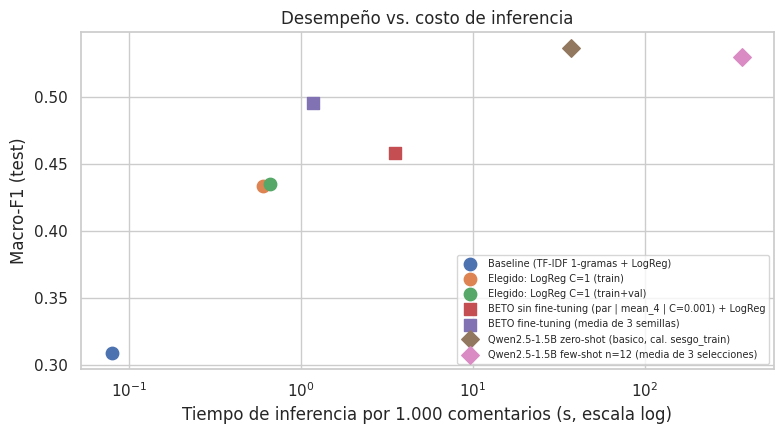

Nota: los tiempos de la parte 2 se midieron en CPU y los de las partes 3 y 4 en GPU.


In [21]:
bloques = []
COLS_COMP = ["macro_f1", "accuracy", "t_train_s", "t_inf_por_1000_s", "tamaño_modelo_MB"]
if os.path.exists("resultados_parte2_test.csv"):
    p2 = pd.read_csv("resultados_parte2_test.csv", index_col=0)
    p2["t_inf_por_1000_s"] = p2["t_inf_por_1000_ms"] / 1000
    bloques.append(p2[COLS_COMP].assign(enfoque="Clásico (parte 2)"))
if os.path.exists("resultados_parte3_test.csv"):
    p3 = pd.read_csv("resultados_parte3_test.csv", index_col=0)
    p3 = p3[p3.index.str.startswith("BETO sin fine-tuning") | (p3.index == "BETO fine-tuning (media de 3 semillas)")]
    bloques.append(p3[COLS_COMP].assign(enfoque="Encoder (parte 3)"))
bloques.append(test_tabla.loc[[NOMBRE_ZS, NOMBRE_FS_MEDIA], COLS_COMP].assign(enfoque="LLM (parte 4)"))

comp = pd.concat(bloques)
display(comp.round(4))

if len(bloques) > 1:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    marcadores = {"Clásico (parte 2)": "o", "Encoder (parte 3)": "s", "LLM (parte 4)": "D"}
    for i, (nombre, f) in enumerate(comp.iterrows()):
        ax.scatter(f["t_inf_por_1000_s"], f["macro_f1"], s=80, color=f"C{i}",
                   marker=marcadores[f["enfoque"]], label=nombre[:60])
    ax.set_xscale("log"); ax.set_xlabel("Tiempo de inferencia por 1.000 comentarios (s, escala log)")
    ax.set_ylabel("Macro-F1 (test)"); ax.set_title("Desempeño vs. costo de inferencia")
    ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()
    print("Nota: los tiempos de la parte 2 se midieron en CPU y los de las partes 3 y 4 en GPU.")
else:
    print("No se encontraron los resultados de las partes 2 y 3: subirlos para ver la comparación (opcional).")

**Observaciones**

Valores de las partes 2 y 3 (por si sus CSV no se suben a Colab):

| Enfoque | Macro-F1 test | Accuracy | F1 favor | F1 against | F1 neutral | Entrenamiento | Inferencia / 1.000 com. | Tamaño |
|---|---|---|---|---|---|---|---|---|
| Clásico: TF-IDF + LogReg (parte 2, train+val) | 0,435 | 0,529 | 0,667 | 0,346 | 0,292 | 3,7 s (CPU) | 0,59 s (CPU) | 1,3 MB |
| BETO congelado + LogReg (parte 3) | 0,458 | 0,502 | 0,604 | 0,459 | 0,311 | 7,6 s (GPU) | 3,5 s (GPU) | 439 MB |
| BETO fine-tuning (parte 3, 3 semillas) | 0,495 ± 0,017 | 0,611 | 0,731 | 0,464 | 0,290 | 72 s (GPU) | 1,2 s (GPU) | 439 MB |
| Qwen2.5-1.5B zero-shot + `sesgo_train` (parte 4) | **0,537** | 0,600 | 0,721 | **0,485** | **0,405** | 8 s (calibración) | 37 s (GPU) | 3.087 MB |
| Qwen2.5-1.5B few-shot n=12 + `sesgo_train` (parte 4, 3 selecciones) | 0,530 ± 0,018 | 0,600 | 0,716 | 0,481 | 0,392 | 75 s (calibración) | 372 s (GPU) | 3.087 MB |

- **Sin ningún fine-tuning, Qwen2.5-1.5B con calibración supera a BETO con fine-tuning** (0,537 contra 0,495 ± 0,017, +4 puntos) y al modelo clásico (+10 puntos). Sin calibrar quedaba por debajo (0,474 en test, sección 4.7). La calibración con 200 comentarios de train es lo que lo pone adelante.
- **La mejora viene casi toda de *neutral*:** F1 0,405 contra 0,290 de BETO (+11,5 puntos), mientras que en *against* es apenas mejor (+2) y en *favor*, igual (−1). La accuracy es similar (0,600 contra 0,611). Con solo 66 comentarios *neutral* en test, la ventaja depende de pocos casos.
- **Los errores son muy distintos:** Qwen zero-shot y BETO fine-tuning (semilla 42) coinciden en solo el 51% de sus predicciones. 88 comentarios los acierta solo Qwen y 77 solo BETO, lo que sugiere que un ensamble podría aprovechar los dos (parte 5).
- **Costo:** la inferencia del zero-shot es ≈32 veces más lenta que BETO con fine-tuning (37 contra 1,2 s cada 1.000 comentarios) y ≈60 veces más lenta que el modelo clásico en CPU. El modelo ocupa 7 veces más (3,1 GB contra 0,44 GB). El few-shot multiplica la inferencia por 10 más, sin mejorar el resultado.

### 4.9. Guardado de resultados

Se guardan los resultados para la comparación entre enfoques (parte 5):
- `resultados_parte4_val.csv`: todos los experimentos (zero-shot y few-shot, con cada método de calibración) sobre validación.
- `resultados_parte4_test.csv`: métricas, tiempos, tokens por prompt, VRAM y tamaño en test.
- `predicciones_parte4_test.csv`: predicciones en test de cada configuración final (para comparaciones por comentario entre enfoques).

In [22]:
res_val.to_csv("resultados_parte4_val.csv", index=False)

test_tabla.assign(modelo_llm=MODELO_LLM, prompt_zs=PROMPT_ZS, calibracion_zs=CAL_ZS,
                  prompt_fs=PROMPT_FS, seleccion_fs=SEL_FS, n_demos_fs=N_FINAL, calibracion_fs=CAL_FS,
                  t_carga_modelo_s=T_CARGA_S, vram_pesos_GB=VRAM_MODELO_GB,
                  gpu=torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"
                  ).to_csv("resultados_parte4_test.csv")

pd.DataFrame({"id": test_df["id"], "label": y_test,
              "pred_zero_shot": preds_test[NOMBRE_ZS],
              **{f"pred_few_shot_n{N_FINAL}_seed{s}": preds_test[f"{PREFIJO_FS} (seed={s})"] for s in SEEDS_DEMOS}}
             ).to_csv("predicciones_parte4_test.csv", index=False)
print("Archivos guardados.")

try:   # en Colab, descarga los archivos para no perderlos al cerrar el entorno
    from google.colab import files
    for f in ["resultados_parte4_val.csv", "resultados_parte4_test.csv", "predicciones_parte4_test.csv"]:
        files.download(f)
except ImportError:
    pass

Archivos guardados.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 4.10. Conclusiones de la parte 4

- **Zero-shot:** el mejor prompt fue `basico` (instrucción simple con el título de la propuesta) con calibración `sesgo_train`, con un Macro-F1 en test de **0,537** (val: 0,546). Sin calibrar, el modelo tiene un sesgo fuerte hacia *against*, porque confunde quejas con rechazo, y el mejor prompt era el que *no* mostraba la propuesta (0,523 en val). La calibración contextual no sirve en esta tarea (las entradas vacías son genuinamente *neutral*), `lote` corrige poco (+2 a +4 puntos) y `sesgo_train`, un sesgo por clase ajustado sobre 200 comentarios de train, corrige el sesgo (+10 puntos en val y +6 en test respecto del mismo prompt sin calibrar).
- **Few-shot:** agregar ejemplos hace que el modelo prediga *neutral* para la mitad de los comentarios, sean balanceados o proporcionales, así que sin calibrar siempre empeora. Con `sesgo_train`, mostrar la propuesta ayuda 2–3 puntos y la selección proporcional supera a la balanceada. La mejor configuración (12 ejemplos proporcionales) obtiene **0,530 ± 0,018** en test, **0,7 puntos menos** que el zero-shot, con 9 veces más tokens por prompt. Más ejemplos mejoran el formato de la respuesta (masa en las etiquetas 0,83 → 0,96), pero no la decisión, y el resultado depende bastante de qué ejemplos tocaron.
- **Comparación:** sin fine-tuning, Qwen2.5-1.5B calibrado queda **por encima** del modelo clásico de la parte 2 (0,435) y de BETO con fine-tuning (0,495 ± 0,017), gracias sobre todo a la clase *neutral*. Sus errores son muy distintos a los de BETO (coinciden en el 51% de las predicciones).
- **Costos:** no requiere fine-tuning (a lo sumo, puntuar 200 comentarios de train para calibrar: 8 s), pero el modelo ocupa ≈3,1 GB en fp16 y la inferencia cuesta ≈37 s cada 1.000 comentarios en una T4 (≈32 veces más que BETO), y crece en forma lineal con la longitud del prompt (372 s con 12 ejemplos).
- **Limitaciones:**
  - Se evaluó un único LLM chico; modelos de 7B o más probablemente aprovechen mejor la propuesta y los ejemplos.
  - La grilla del sesgo (±4) quedó chica: el sesgo de *against* en zero-shot y el de *neutral* en few-shot tocaron el borde, así que el few-shot calibrado podría estar algo subestimado.
  - El sesgo se ajusta con solo 200 comentarios, por lo que es ruidoso (en algún prompt empeora en validación).
  - El scoring por primer token incluye tokens genéricos para las variantes con mayúscula (`F` para *Favor*, `Con` para *Contra*).
  - Con ≈65 comentarios *neutral* por conjunto, diferencias de 2–3 puntos no son concluyentes.